# The founder SV-burden model

**One model, reported on its own.** Alternative specifications — the `shared` origin filter, dropping the
reference-TE term, omitting the local-adaptation control, the split insertion/deletion parameterisation,
single-technology panels — were all fitted, and are indexed in `results/sv_adaptive/model_specs.csv` and
`model_registry.csv`. None is shown here: carrying retired arms through the figures made the result harder
to read, not easier.

## The model, exactly as run

```r
y ~ snp_CDS + sv_CDS + sv_TE + sv_promoter + sv_intergenic + cactus
    + sv_ctx:bio1c   for each of the six contexts
    + obio1c + obio1c:bio1c
    + (1 | garden) + (1 | kin) + (0 + obio1c | garden)
    + (0 + sv_ctx | garden)   for each of the six contexts
```

Fitted with `lme4qtl::relmatLmer`, kinship passed as `relmat`, on **all 231 founders × 31 gardens =
7,161 rows** — 151 short-read plus 80 cactus-assembly founders, with assembly route entering as the
covariate `cactus` rather than as a subset.

**Burdens.** Truvari-collapsed SV **events**, insertions and deletions pooled, one genomic context each by
first match (CDS > UTR > intron > reference TE > promoter ≤ 2 kb > intergenic). No origin filter — every
variant passing call rate ≥ 90 % and ≥ 2 carriers enters:

```
sv_<ctx>  =  z( (ins carried + del carried) / (ins called + del called) )
```

| symbol | meaning |
|---|---|
| `bio1c` | the **garden's** mean annual temperature, centred on the mean of the 31 gardens |
| `obio1c` | the **founder's origin** bio1, centred over the 231 founders |
| `obio1c:bio1c` | **local adaptation**: origin climate × garden climate, containing no SV information |
| `snp_CDS` | matching SNP coding burden · `cactus` = assembly route (0/1) |
| `kin` | founder random effect with covariance σ²K, K = SNP kinship |
| `(0 + sv_ctx \| garden)` | independent random garden slope per modelled burden |
| `(0 + obio1c \| garden)` | local adaptation gets its own strength in each garden |

Insertions and deletions are **pooled** because which label a variant receives depends on the Col-0
reference and is not a biological distinction — the same reason the site-frequency spectra in Figure 1 are
folded.

The independent founder intercept `fid` is **pruned**. In the unpruned fit its variance was 4.9 × 10⁻⁷ —
it carried nothing, all founder-level variation being absorbed by kinship — so removing it costs one
parameter and leaves no component at the boundary. The two fits agree in log-likelihood (−11501.0028) and
in every coefficient and standard error to five decimal places.

## Reading the coefficients

`bio1c` is centred, so each burden splits into two numbers that are read together:

- **`sv_ctx`** — the burden's effect **at a garden of average temperature** (13.5 °C): *are SVs in this
  context deleterious?*
- **`sv_ctx:bio1c`** — how that effect **changes per °C** of garden temperature.

Both come out of this one fit; no separate main-effects model is needed or used.

⚠ `obio1c:bio1c` is itself an interaction, so it is near-orthogonal to the burden main effects: it tests
the `sv_ctx:bio1c` terms hard and the `sv_ctx` terms only mildly. §13 returns to this.

In [1]:

import os, glob
import numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi":120,"font.size":8,"axes.linewidth":0.6,"savefig.bbox":"tight","legend.frameon":False})
G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive")); os.makedirs(f"{G}/plots",exist_ok=True)
# colours: insertions forest green, deletions orange, SNPs grey; dark -> light = coding -> promoter -> intergenic
# (no blue or red: those are the garden-temperature scale)
PAL={"snp_CDS":"0.25","snp_promoter":"0.45","snp_intergenic":"0.65",
     "ins_CDS":"#2F4A1F","ins_promoter":"#4E6B3A","ins_intergenic":"#9DB58C",
     "del_CDS":"#B04A00","del_promoter":"#F07A2E","del_intergenic":"#F8BE91"}; PC=lambda t: PAL[t.split(":")[0]]         # colour of a term (interactions take their term's colour)
def style(a,axis="x"):
    a.set_axisbelow(True); a.grid(color="0.9",lw=0.6,axis=axis)
    for s_ in a.spines.values(): s_.set_visible(False)
def panel(a,letter,x=-0.08,y=1.04): a.annotate(letter,xy=(x,y),xycoords="axes fraction",fontsize=11,fontweight="bold",ha="right")
M="\u2212"
def pct(v,d=3): return f"{v:+.{d}g}%".replace("-",M)
NBPLOTS=os.path.join(os.getcwd(),"plots"); os.makedirs(NBPLOTS,exist_ok=True)          # notebooks/plots/, for the figures kept with the notebook
def save(fig,name,nb=False):
    for d in ([f"{G}/plots"]+([NBPLOTS] if nb else [])):
        fig.savefig(f"{d}/{name}.png",dpi=200,bbox_inches="tight"); fig.savefig(f"{d}/{name}.pdf",bbox_inches="tight")


In [2]:

PA=f"{G}/final_models_pooled_all"
SUF="_x_obio1cobio1cbio1c_re0obio1cgarden_all6_refid_intall"   # THE model: all six contexts, each
                                                           # with its own temperature interaction
SCS="_x_obio1cobio1cbio1c_all6"                            # RE_DROP and INTER_SET do not change the
                                                           # burdens, so the scale file carries neither
SVT=["sv_CDS","sv_UTR","sv_intron","sv_TE","sv_promoter","sv_intergenic"]   # every context now carries
                                                           # its own temperature interaction
BURD=["snp_CDS","sv_CDS","sv_UTR","sv_intron","sv_TE","sv_promoter","sv_intergenic"]
PAL2={"snp_CDS":"0.25","sv_CDS":"#4A3B6B","sv_UTR":"#5A4A7E","sv_intron":"#6B5A8E",
      "sv_TE":"#B04A00","sv_promoter":"#9084AE","sv_intergenic":"#C6BCD8",
      "cactus":"0.6","obio1c":"#8C6D1F"}
PC2=lambda t: PAL2[("obio1c" if "obio1c" in t else t.split(":")[0])]
LAB2=lambda t: {"snp_CDS":"SNPs, coding","sv_CDS":"SVs, coding","sv_UTR":"SVs, UTR",
                "sv_intron":"SVs, intron","sv_TE":"SVs, reference TE","sv_promoter":"SVs, promoter",
                "sv_intergenic":"SVs, intergenic","cactus":"assembly route",
                "obio1c":"founder origin climate"}[("obio1c" if "obio1c" in t else t.split(":")[0])]
CO=pd.read_csv(f"{PA}/coef_M2p_reml{SUF}.csv").set_index("term")
VC=pd.read_csv(f"{PA}/varcomp_M2p_reml{SUF}.csv")
GD=pd.read_csv(f"{PA}/garden_M2p_reml{SUF}.csv")
VV=pd.read_csv(f"{PA}/vcov_M2p_reml{SUF}.csv",index_col=0)
LLR=pd.read_csv(f"{PA}/loglik_M2p_reml{SUF}.csv").iloc[0]
# LRTs from the NAMED loglik files -- this directory also holds SUBSET=, RE_DROP= and other EXTRA_FIXED
# runs, and a glob would silently mix likelihoods from models fitted on different data
ll=lambda n: pd.read_csv(f"{PA}/loglik_{n}{SUF}.csv").logLik[0]
LRT={t: stats.chi2.sf(2*(ll("M2p_ml")-ll(f"M2p_ml_drop_{t}")),1) for t in SVT}
OBX=next(t for t in CO.index if set(t.split(":"))=={"obio1c","bio1c"})   # lme4 spells it bio1c:obio1c

# PERMUTATION NULL for the interactions. Each replicate shuffles which temperature belongs to which
# garden and refits the whole model: founders keep their burdens and their kinship, gardens keep their own
# mean fitness, and only the garden-identity/temperature pairing is destroyed. obio1c:bio1c is nulled by
# the same shuffle, so no term may track real garden temperature.
# Why the interactions need it and the main effects do not: these terms carry only 31 gardens of
# information and their garden random slopes sit at the variance boundary, so the asymptotic SE is too
# small -- the null SD of z runs 0.99-1.26 instead of 1. For the MAIN effects a Freedman-Lane permutation
# and a residual bootstrap (20k each, perm_main_effects.csv / boot_main_effects.csv) agree with the Wald
# values to three decimals, so those are reported as fitted.
import glob as _glob
PERM=pd.concat([pd.read_csv(f) for f in _glob.glob(f"{PA}/perm/perm_M2p_reml{SUF}_*.csv")],ignore_index=True)
NPERM=int(PERM.seed.nunique())
def _pp(term):
    nz=PERM[PERM.term==term].z.to_numpy()
    return (np.sum(np.abs(nz)>=abs(CO.loc[term,"z"]))+1)/(len(nz)+1)
PP={t: _pp(f"{t}:bio1c") for t in SVT}                       # permutation p per interaction
PSD={t: PERM[PERM.term==f"{t}:bio1c"].z.std(ddof=1) for t in SVT}
PP_LA=_pp(OBX); PSD_LA=PERM[PERM.term==OBX].z.std(ddof=1)
print(f"permutation null loaded: {NPERM} replicates")

SCL=pd.read_csv(f"{PA}/pooled_rate_scale{SCS}.csv").set_index("context")
VPS={f"sv_{c}": SCL.loc[c,"sd_rate"]*SCL.loc[c,"med_called"] for c in SCL.index}
VPS["snp_CDS"]=pd.read_csv(f"{G}/sv_burden_full_model_event_CDS+promoter.csv").set_index("term").variants_per_sd["snp_CDS"]
PV=lambda t: 100/VPS[t.split(":")[0]]                      # per SD -> % per carried variant (display only)

FB=pd.read_csv(f"{G}/founder_burden_event.csv"); sd_ob=FB.bio1.std(ddof=1)
gbn=pd.read_csv(f"{G}/onestage_all/long.csv").drop_duplicates("garden").bio1
cac=(FB.is_cactus.astype(str)=="True")
print(f"founders {len(FB)} = {int((~cac).sum())} short-read + {int(cac.sum())} cactus   "
      f"gardens {len(gbn)}   rows {len(FB)*len(gbn):,}")
print(f"origin bio1 {FB.bio1.min():.1f} to {FB.bio1.max():.1f} degC (SD {sd_ob:.2f});  "
      f"garden bio1 {gbn.min():.1f} to {gbn.max():.1f} degC (mean {gbn.mean():.2f} = where bio1c is zero)")
print(f"\nlogLik {LLR.logLik:.4f}   df {int(LLR.df)}   singular {LLR.singular}")
print("\nvariance components (none at the boundary):"); print(VC.to_string(index=False))
print("\nvariants per SD of each burden (the per-carried-variant divisor):")
for c in SCL.index: print(f"  sv_{c:<11} {VPS['sv_'+c]:8.1f} variants")


permutation null loaded: 1000 replicates


founders 231 = 151 short-read + 80 cactus   gardens 31   rows 7,161
origin bio1 -4.3 to 22.7 degC (SD 4.23);  garden bio1 6.0 to 21.6 degC (mean 13.51 = where bio1c is zero)

logLik -11079.9776   df 27   singular True

variance components (none at the boundary):
     grp          var1         vcov
     kin   (Intercept) 2.533678e-01
  garden        obio1c 9.306379e-03
garden.1 sv_intergenic 1.904945e-02
garden.2   sv_promoter 1.218703e-02
garden.3         sv_TE 0.000000e+00
garden.4     sv_intron 5.490025e-03
garden.5        sv_UTR 3.778473e-02
garden.6        sv_CDS 2.726001e-09
garden.7   (Intercept) 2.538465e-01
Residual           NaN 1.151050e+00

variants per SD of each burden (the per-carried-variant divisor):
  sv_CDS             19.2 variants
  sv_UTR             25.3 variants
  sv_intron          52.2 variants
  sv_TE              53.9 variants
  sv_promoter       143.5 variants
  sv_intergenic      63.2 variants


## 1 · What enters the model

Every truvari-collapsed SV event passing call rate ≥ 90 % and ≥ 2 carriers, split by class so the quantity
the pooling merges is visible: the burden for a context is the green plus the orange segment.

All six contexts carry their own burden term and their own garden-temperature interaction, so every
passing event is in exactly one burden.

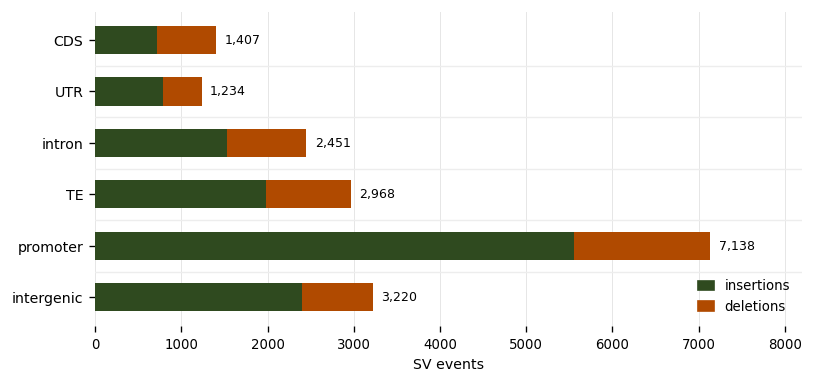

SV events entering the pooled burdens, by context:
            insertions  deletions  pooled total  in the model
CDS                715        692          1407          True
UTR                790        444          1234          True
intron            1532        919          2451          True
TE                1985        983          2968          True
promoter          5557       1581          7138          True
intergenic        2402        818          3220          True

TOTAL 18,418 events


In [3]:

CAT=pd.read_csv(f"{G}/sv_event_catalog.csv"); AP=CAT[CAT.passes]
CTX6=["CDS","UTR","intron","TE","promoter","intergenic"]; MODC=set(CTX6)
CI,CD="#2F4A1F","#B04A00"
fig,a=plt.subplots(figsize=(7.6,3.4)); style(a)
for i,c in enumerate(CTX6):
    ni=int(((AP.context==c)&(AP.kind=="ins")).sum()); nd=int(((AP.context==c)&(AP.kind=="del")).sum())
    a.barh(i,ni,height=0.55,color=CI,lw=0); a.barh(i,nd,height=0.55,left=ni,color=CD,lw=0)
    a.annotate(f"{ni+nd:,}",xy=(ni+nd,i),xytext=(5,0),textcoords="offset points",va="center",fontsize=7.5)
    if i<len(CTX6)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.set_yticks(range(len(CTX6)))
a.set_yticklabels([c+("" if c in MODC else "  (not a model term)") for c in CTX6],fontsize=8.5)
a.invert_yaxis(); a.set_xlabel("SV events",fontsize=8.5); a.set_xlim(0,8200)
a.legend([plt.Rectangle((0,0),1,1,color=CI),plt.Rectangle((0,0),1,1,color=CD)],
         ["insertions","deletions"],fontsize=8,loc="lower right",handlelength=1.2)
save(fig,"model_inputs",nb=True); plt.show()
T=pd.DataFrame({"insertions":[int(((AP.context==c)&(AP.kind=="ins")).sum()) for c in CTX6],
                "deletions":[int(((AP.context==c)&(AP.kind=="del")).sum()) for c in CTX6]},index=CTX6)
T["pooled total"]=T.insertions+T.deletions; T["in the model"]=[c in MODC for c in CTX6]
print("SV events entering the pooled burdens, by context:"); print(T.to_string())
print(f"\nTOTAL {int(T['pooled total'].sum()):,} events")


## 2 · The burden effects

The effect of each burden **at a garden of average temperature**, in % fitness per carried variant
(± 95 % CI). `bio1c` is centred, so this is what the `sv_ctx` coefficients mean; how each effect changes
with temperature is §3.

Filled markers are p < 0.05.

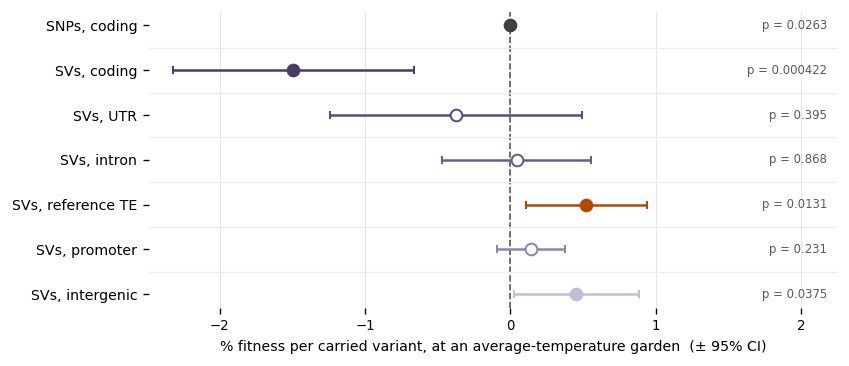

BURDEN EFFECTS at an average-temperature garden, % fitness per carried variant:

             term %/variant           95% CI           per SD   Wald p
     SNPs, coding   -0.0047 [-0.009, -0.001] -0.4687 ± 0.2109  0.02627
      SVs, coding   -1.4945 [-2.325, -0.664] -0.2864 ± 0.0812 0.000422
         SVs, UTR   -0.3764 [-1.244, +0.492] -0.0953 ± 0.1121   0.3954
      SVs, intron   +0.0435 [-0.467, +0.554] +0.0227 ± 0.1360   0.8676
SVs, reference TE   +0.5241 [+0.110, +0.938] +0.2823 ± 0.1138   0.0131
    SVs, promoter   +0.1441 [-0.092, +0.380] +0.2067 ± 0.1725   0.2306
  SVs, intergenic   +0.4553 [+0.026, +0.884] +0.2878 ± 0.1383  0.03746

nuisance terms: intercept -1.2153, cactus -0.0090 (p = 0.945)


In [4]:

fig,a=plt.subplots(figsize=(7.4,3.2)); style(a); a.axvline(0,color="0.35",lw=1,ls="--")
for i,t in enumerate(BURD):
    e,se=CO.loc[t,"estimate"]*PV(t), CO.loc[t,"se"]*PV(t)
    a.errorbar(e,i,xerr=1.96*se,fmt="o",color=PC2(t),mfc=PC2(t) if CO.loc[t,"p"]<0.05 else "white",
               mew=1.2,ms=7,capsize=2.5,zorder=3)
    if i<len(BURD)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.set_yticks(range(len(BURD))); a.set_yticklabels([LAB2(t) for t in BURD],fontsize=8.5); a.invert_yaxis()
x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.32*(x1-x0))
for i,t in enumerate(BURD):
    a.annotate(f"p = {CO.loc[t,'p']:.3g}",xy=(0.985,i),xycoords=("axes fraction","data"),
               ha="right",va="center",fontsize=7,color="0.35")
a.set_xlabel("% fitness per carried variant, at an average-temperature garden  (± 95% CI)",fontsize=8.5)
save(fig,"model_burden_effects",nb=True); plt.show()
print("BURDEN EFFECTS at an average-temperature garden, % fitness per carried variant:\n")
print(pd.DataFrame([{"term":LAB2(t),"%/variant":f"{CO.loc[t,'estimate']*PV(t):+.4f}",
    "95% CI":f"[{(CO.loc[t,'estimate']-1.96*CO.loc[t,'se'])*PV(t):+.3f}, "
             f"{(CO.loc[t,'estimate']+1.96*CO.loc[t,'se'])*PV(t):+.3f}]",
    "per SD":f"{CO.loc[t,'estimate']:+.4f} ± {CO.loc[t,'se']:.4f}",
    "Wald p":f"{CO.loc[t,'p']:.4g}"} for t in BURD]).to_string(index=False))
print(f"\nnuisance terms: intercept {CO.loc['(Intercept)','estimate']:+.4f}, "
      f"cactus {CO.loc['cactus','estimate']:+.4f} (p = {CO.loc['cactus','p']:.3g})")


## 3 · The garden-temperature interactions

How each burden's effect **changes per °C** of garden temperature, in % per carried variant per °C
(± 95 % CI).

**Significance here is a permutation p-value, not the model's own.** Each of 1,000 replicates shuffles
which temperature belongs to which garden and refits the whole model, so founders keep their burdens and
kinship, gardens keep their own mean fitness, and only the garden-identity ↔ temperature pairing is
destroyed. This is necessary because these terms carry just **31 gardens** of information and their garden
random slopes sit at the variance boundary: under the null the SD of the z statistic runs **0.99–1.26**
instead of 1, so the Wald and LRT p-values are anti-conservative. Both are printed alongside so the size
of the correction is visible.

The **main effects are not treated this way** — there a Freedman-Lane permutation and a residual bootstrap
(20,000 replicates each) reproduce the Wald p-values to three decimals, so §2 reports them as fitted.

Filled markers are permutation p < 0.05; p-values are uncorrected.

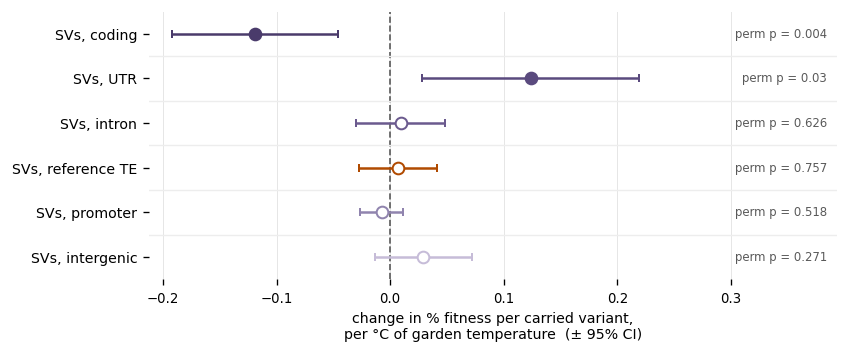

BURDEN x GARDEN TEMPERATURE, % per carried variant per degC:

             term %/variant/degC             95% CI  Wald p   LRT p PERMUTATION p null SD of z  p < 0.05
      SVs, coding       -0.11895 [-0.1919, -0.0460] 0.00139 0.00262         0.004         1.10      True
         SVs, UTR       +0.12363 [+0.0280, +0.2192]  0.0113  0.0122          0.03         1.16      True
      SVs, intron       +0.00922 [-0.0299, +0.0484]   0.645   0.641         0.626         0.99     False
SVs, reference TE       +0.00691 [-0.0273, +0.0411]   0.692   0.692         0.757         1.23     False
    SVs, promoter       -0.00747 [-0.0267, +0.0117]   0.446   0.442         0.518         1.16     False
  SVs, intergenic       +0.02925 [-0.0135, +0.0720]   0.179   0.178         0.271         1.25     False

  2 of 6 interactions reach permutation p < 0.05 (1000 replicates).
  local adaptation (obio1c:bio1c): Wald p 0.04257  ->  permutation p 0.05195   null SD of z 1.03

  null SD of z would be 1.00 for a c

In [5]:

fig,a=plt.subplots(figsize=(7.4,2.9)); style(a); a.axvline(0,color="0.35",lw=1,ls="--")
for i,t in enumerate(SVT):
    n=f"{t}:bio1c"; e,se=CO.loc[n,"estimate"]*PV(t), CO.loc[n,"se"]*PV(t)
    a.errorbar(e,i,xerr=1.96*se,fmt="o",color=PC2(t),mfc=PC2(t) if PP[t]<0.05 else "white",
               mew=1.2,ms=7,capsize=2.5,zorder=3)
    if i<len(SVT)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.set_yticks(range(len(SVT))); a.set_yticklabels([LAB2(t) for t in SVT],fontsize=8.5); a.invert_yaxis()
a.set_ylim(len(SVT)-0.5,-0.5)
x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.34*(x1-x0))
for i,t in enumerate(SVT):
    a.annotate(f"perm p = {PP[t]:.3g}",xy=(0.985,i),xycoords=("axes fraction","data"),
               ha="right",va="center",fontsize=7,color="0.35")
a.set_xlabel("change in % fitness per carried variant,\nper °C of garden temperature  (± 95% CI)",fontsize=8.5)
save(fig,"model_interactions",nb=True); plt.show()
print("BURDEN x GARDEN TEMPERATURE, % per carried variant per degC:\n")
print(pd.DataFrame([{"term":LAB2(t),"%/variant/degC":f"{CO.loc[t+':bio1c','estimate']*PV(t):+.5f}",
    "95% CI":f"[{(CO.loc[t+':bio1c','estimate']-1.96*CO.loc[t+':bio1c','se'])*PV(t):+.4f}, "
             f"{(CO.loc[t+':bio1c','estimate']+1.96*CO.loc[t+':bio1c','se'])*PV(t):+.4f}]",
    "Wald p":f"{CO.loc[t+':bio1c','p']:.3g}","LRT p":f"{LRT[t]:.3g}",
    "PERMUTATION p":f"{PP[t]:.3g}","null SD of z":f"{PSD[t]:.2f}",
    "p < 0.05":PP[t]<0.05} for t in SVT]).to_string(index=False))
print(f"\n  {sum(PP[t]<0.05 for t in SVT)} of {len(SVT)} interactions reach permutation p < 0.05 "
      f"({NPERM} replicates).")
print(f"  local adaptation (obio1c:bio1c): Wald p {CO.loc[OBX,'p']:.4g}  ->  "
      f"permutation p {PP_LA:.4g}   null SD of z {PSD_LA:.2f}")
print("\n  null SD of z would be 1.00 for a calibrated Wald test; every interaction exceeds it,")
print("  so the asymptotic p-values are anti-conservative and the permutation ones are reported.")


## 4 · How big is local adaptation, next to the burden interactions?

Burden coefficients are per SD of the standardised rate; `obio1c` is entered **centred but not
standardised**, so its coefficient is per °C of origin climate. Multiplying it by the SD of founder origin
bio1 puts both on one scale: change in log-fitness **per SD of the predictor, per °C of garden
temperature**. All values are from the fitted model.

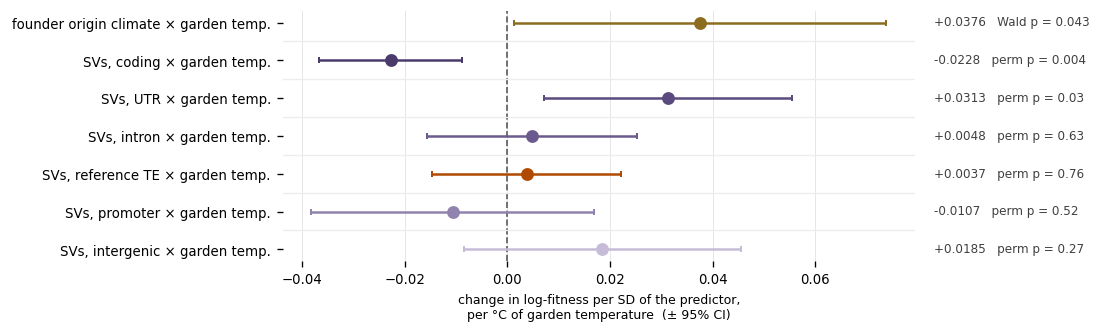

all x temperature terms on one scale (per SD of predictor, per degC of garden):
  founder origin climate x garden temp.      +0.03757   (1.00x the local-adaptation term)
  SVs, coding x garden temp.                 -0.02280   (0.61x the local-adaptation term)
  SVs, UTR x garden temp.                    +0.03130   (0.83x the local-adaptation term)
  SVs, intron x garden temp.                 +0.00481   (0.13x the local-adaptation term)
  SVs, reference TE x garden temp.           +0.00372   (0.10x the local-adaptation term)
  SVs, promoter x garden temp.               -0.01071   (0.29x the local-adaptation term)
  SVs, intergenic x garden temp.             +0.01848   (0.49x the local-adaptation term)


In [6]:

TT=[(OBX,sd_ob)]+[(f"{t}:bio1c",1.0) for t in SVT]
fig,a=plt.subplots(figsize=(6.8,2.7)); style(a); a.axvline(0,color="0.35",lw=1,ls="--")
for i,(n,k) in enumerate(TT):
    e,se=CO.loc[n,"estimate"]*k, CO.loc[n,"se"]*k
    a.errorbar(e,i,xerr=1.96*se,fmt="o",color=PC2(n),ms=6.5,mew=1.2,capsize=2,zorder=3)
    # annotate the same statistic section 3 reports -- the likelihood-ratio p -- so the same term cannot
    # appear to differ between sections. The local-adaptation term has no LRT refit, so it carries its Wald p.
    lab=(f"perm p = {PP[n.split(':')[0]]:.2g}" if n.split(":")[0] in PP
         else f"Wald p = {CO.loc[n,'p']:.2g}")
    a.annotate(f"{e:+.4f}   {lab}",xy=(1.03,i),xycoords=("axes fraction","data"),
               va="center",fontsize=7.2,color="0.25",annotation_clip=False)
    if i<len(TT)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.set_yticks(range(len(TT))); a.set_yticklabels([LAB2(n)+" × garden temp." for n,_ in TT],fontsize=8)
a.invert_yaxis()
a.set_xlabel("change in log-fitness per SD of the predictor,\nper °C of garden temperature  (± 95% CI)",fontsize=7.5)
save(fig,"model_local_adaptation_scale",nb=True); plt.show()
ob=CO.loc[OBX,"estimate"]*sd_ob
print("all x temperature terms on one scale (per SD of predictor, per degC of garden):")
for n,k in TT:
    e=CO.loc[n,"estimate"]*k
    print(f"  {LAB2(n)+' x garden temp.':<42} {e:+.5f}   ({abs(e/ob):.2f}x the local-adaptation term)")


## 5 · The fitted effect in each garden

Each garden's own total effect of the coding-SV burden, **from the fitted model** — the fixed part, plus
the temperature term, plus that garden's random slope — in % per carried variant. Every covariate is in:
kinship, the SNP coding burden, assembly route, origin climate and the other burdens. These are not
separate per-garden regressions. **Left:** gardens sorted by effect, coloured by
garden temperature; bars are ± 1.96 conditional SD of the slope, and the line and band are the effect at
the average garden ± 95 % CI. **Right:** the same against garden temperature, with the model's fitted line.

⚠ The points are **conditional modes from the same model that fitted the line**, so noisy gardens are
shrunk towards it. Their agreement with the line is partly by construction; the test is the fixed-effect
slope and its LRT, not the scatter.

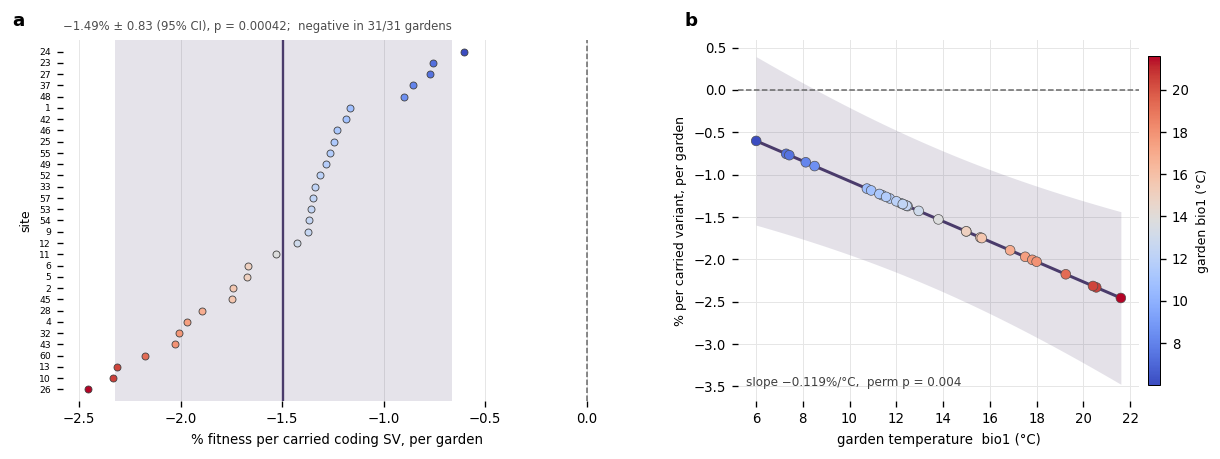

coding-SV effect per garden: -2.46% .. -0.60%, negative in 31/31 gardens


In [7]:

T="sv_CDS"; sc=PV(T)
g=GD[GD.term==T]; b=sc*g.total.to_numpy(); e=1.96*sc*g.cond_sd.to_numpy(); xg=g.bio1.to_numpy()
NORM=mpl.colors.Normalize(xg.min(),xg.max()); CM=plt.get_cmap("coolwarm"); bc=xg.mean()
fig=plt.figure(figsize=(11.8,3.9)); gs=fig.add_gridspec(1,2,width_ratios=[1.3,1],wspace=0.26)
a=fig.add_subplot(gs[0,0]); style(a); panel(a,"a",x=-0.07); a.axvline(0,color="0.4",lw=0.9,ls="--")
o=np.argsort(b); b0_=sc*CO.loc[T,"estimate"]; s0_=sc*CO.loc[T,"se"]
a.axvspan(b0_-1.96*s0_,b0_+1.96*s0_,color=PC2(T),alpha=0.14,lw=0); a.axvline(b0_,color=PC2(T),lw=1.4)
for yi,j in enumerate(o):
    a.errorbar(b[j],yi,xerr=e[j],fmt="o",ms=4.2,color=CM(NORM(xg[j])),mec="0.25",mew=0.5,
               ecolor=CM(NORM(xg[j])),elinewidth=1.0,capsize=1.6)
a.set_yticks(range(len(g))); a.set_yticklabels(g.garden.to_numpy()[o].astype(int),fontsize=5.5)
a.set_ylim(-1,len(g)); a.set_ylabel("site",fontsize=7.5)
a.annotate(f"{pct(b0_)} ± {1.96*s0_:.2g} (95% CI), p = {CO.loc[T,'p']:.2g};  "
           f"negative in {(b<0).sum()}/{len(g)} gardens",xy=(0,1.02),xycoords="axes fraction",
           fontsize=7,color="0.3",va="bottom")
a.set_xlabel("% fitness per carried coding SV, per garden",fontsize=8)
a=fig.add_subplot(gs[0,1]); style(a,axis="both"); panel(a,"b",x=-0.10); a.axhline(0,color="0.4",lw=0.9,ls="--")
a.errorbar(xg,b,yerr=e,fmt="none",ecolor="0.85",elinewidth=0.8,zorder=1)
a.scatter(xg,b,s=34,c=xg,cmap=CM,norm=NORM,linewidth=0.4,edgecolor="0.3",zorder=3)
xx=np.linspace(xg.min(),xg.max(),60); xc=xx-bc; i0,i1=T,f"{T}:bio1c"
fit=CO.loc[i0,"estimate"]+CO.loc[i1,"estimate"]*xc
v=VV.loc[i0,i0]+xc**2*VV.loc[i1,i1]+2*xc*VV.loc[i0,i1]
a.fill_between(xx,sc*(fit-1.96*np.sqrt(v)),sc*(fit+1.96*np.sqrt(v)),color=PC2(T),alpha=0.15,lw=0)
a.plot(xx,sc*fit,color=PC2(T),lw=1.8)
a.annotate(f"slope {pct(sc*CO.loc[i1,'estimate'])}/°C,  perm p = {PP[T]:.2g}",
           xy=(0.02,0.04),xycoords="axes fraction",fontsize=7.2,color="0.25")
a.set_xlabel("garden temperature  bio1 (°C)",fontsize=8)
a.set_ylabel("% per carried variant, per garden",fontsize=7.5)
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORM,cmap=CM),ax=a,pad=0.02,fraction=0.03,aspect=26)
cb.set_label("garden bio1 (°C)",fontsize=7.5)
save(fig,"model_by_garden",nb=True); plt.show()
print(f"coding-SV effect per garden: {b.min():+.2f}% .. {b.max():+.2f}%, "
      f"negative in {(b<0).sum()}/{len(g)} gardens")


### Every burden, garden by garden

The same quantity for each burden that carries a temperature interaction, so the coding result can be read
against the others. Each point is one garden's **total** effect from the full model — fixed part + its
temperature term + that garden's random slope — with every covariate held in: kinship, the SNP coding
burden, assembly route, origin climate, local adaptation fitted per garden, and the other burdens
simultaneously. **Red** marks gardens where the effect is positive. The line is the model's fitted
temperature trend with its 95 % CI.

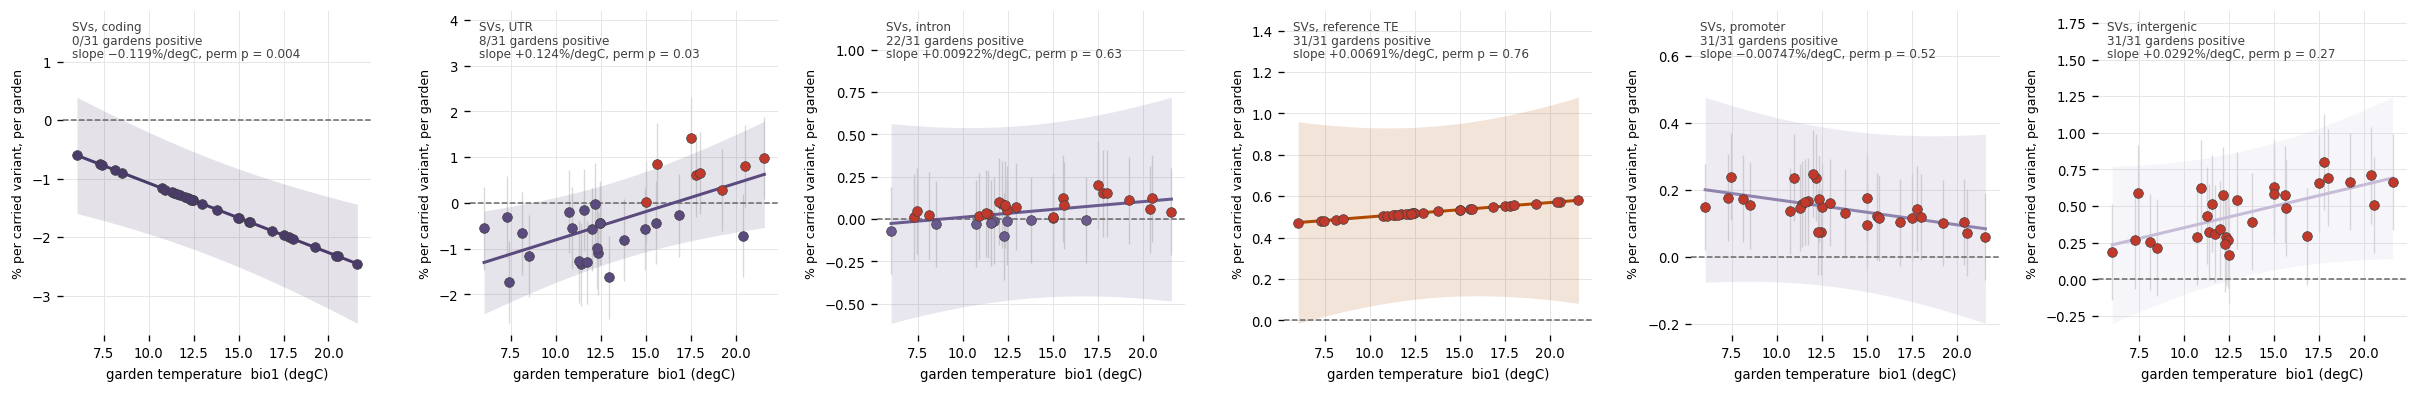

SVs, coding          per garden -2.457% .. -0.602%   positive in  0/31 gardens
SVs, UTR             per garden -1.734% .. +1.410%   positive in  8/31 gardens
SVs, intron          per garden -0.102% .. +0.198%   positive in 22/31 gardens
SVs, reference TE    per garden +0.472% .. +0.580%   positive in 31/31 gardens
SVs, promoter        per garden +0.060% .. +0.248%   positive in 31/31 gardens
SVs, intergenic      per garden +0.165% .. +0.803%   positive in 31/31 gardens


In [8]:

fig,axs=plt.subplots(1,len(SVT),figsize=(4.2*len(SVT),3.5))
for a,T in zip(np.atleast_1d(axs),SVT):
    style(a,axis="both"); a.axhline(0,color="0.4",lw=0.9,ls="--")
    sc=PV(T); g=GD[GD.term==T]; b=sc*g.total.to_numpy(); xg=g.bio1.to_numpy()
    er=1.96*sc*g.cond_sd.to_numpy(); pos=b>0
    a.errorbar(xg,b,yerr=er,fmt="none",ecolor="0.85",elinewidth=0.8,zorder=1)
    a.scatter(xg[~pos],b[~pos],s=34,color=PC2(T),edgecolor="0.25",linewidth=0.4,zorder=3)
    a.scatter(xg[pos],b[pos],s=34,color="#C0392B",edgecolor="0.25",linewidth=0.4,zorder=3)
    xx=np.linspace(xg.min(),xg.max(),60); xc=xx-xg.mean(); i1=f"{T}:bio1c"
    fit=CO.loc[T,"estimate"]+CO.loc[i1,"estimate"]*xc
    v=VV.loc[T,T]+xc**2*VV.loc[i1,i1]+2*xc*VV.loc[T,i1]
    a.fill_between(xx,sc*(fit-1.96*np.sqrt(v)),sc*(fit+1.96*np.sqrt(v)),color=PC2(T),alpha=0.15,lw=0)
    a.plot(xx,sc*fit,color=PC2(T),lw=1.8,zorder=2)
    a.annotate(f"{LAB2(T)}\n{(b>0).sum()}/{len(g)} gardens positive\n"
               f"slope {pct(sc*CO.loc[i1,'estimate'])}/degC, perm p = {PP[T]:.2g}",
               xy=(0.03,0.97),xycoords="axes fraction",va="top",ha="left",fontsize=7.2,color="0.25")
    y0,y1=a.get_ylim(); a.set_ylim(y0,y1+0.30*(y1-y0))
    a.set_xlabel("garden temperature  bio1 (degC)",fontsize=8)
    a.set_ylabel("% per carried variant, per garden",fontsize=7.5)
fig.subplots_adjust(wspace=0.32)
save(fig,"model_by_garden_all",nb=True); plt.show()
for T in SVT:
    g=GD[GD.term==T]; b=PV(T)*g.total.to_numpy()
    print(f"{LAB2(T):20s} per garden {b.min():+.3f}% .. {b.max():+.3f}%   "
          f"positive in {(b>0).sum():2d}/{len(g)} gardens")


### Garden by garden, as the model fits it

The panel you asked for, one per garden, ordered by garden temperature — but the y axis is **not** raw
ecotype fitness and the line is **not** a per-garden regression of fitness on burden.

Each point is a **partial residual** from the full model: that founder's fitness in that garden with every
other covariate already removed — kinship, the SNP coding burden, assembly route, origin climate, local
adaptation fitted per garden, and the other burden. The coloured line is that garden's **conditional**
effect from the model, fixed part + temperature term + its random slope; by construction it is the slope
through those points. The grey dashed line is the raw within-garden regression of fitness on burden, with
nothing controlled, so the two can be read against each other.

The number in each panel is the model's slope for that garden, in % per carried variant, printed **red**
where it is positive.

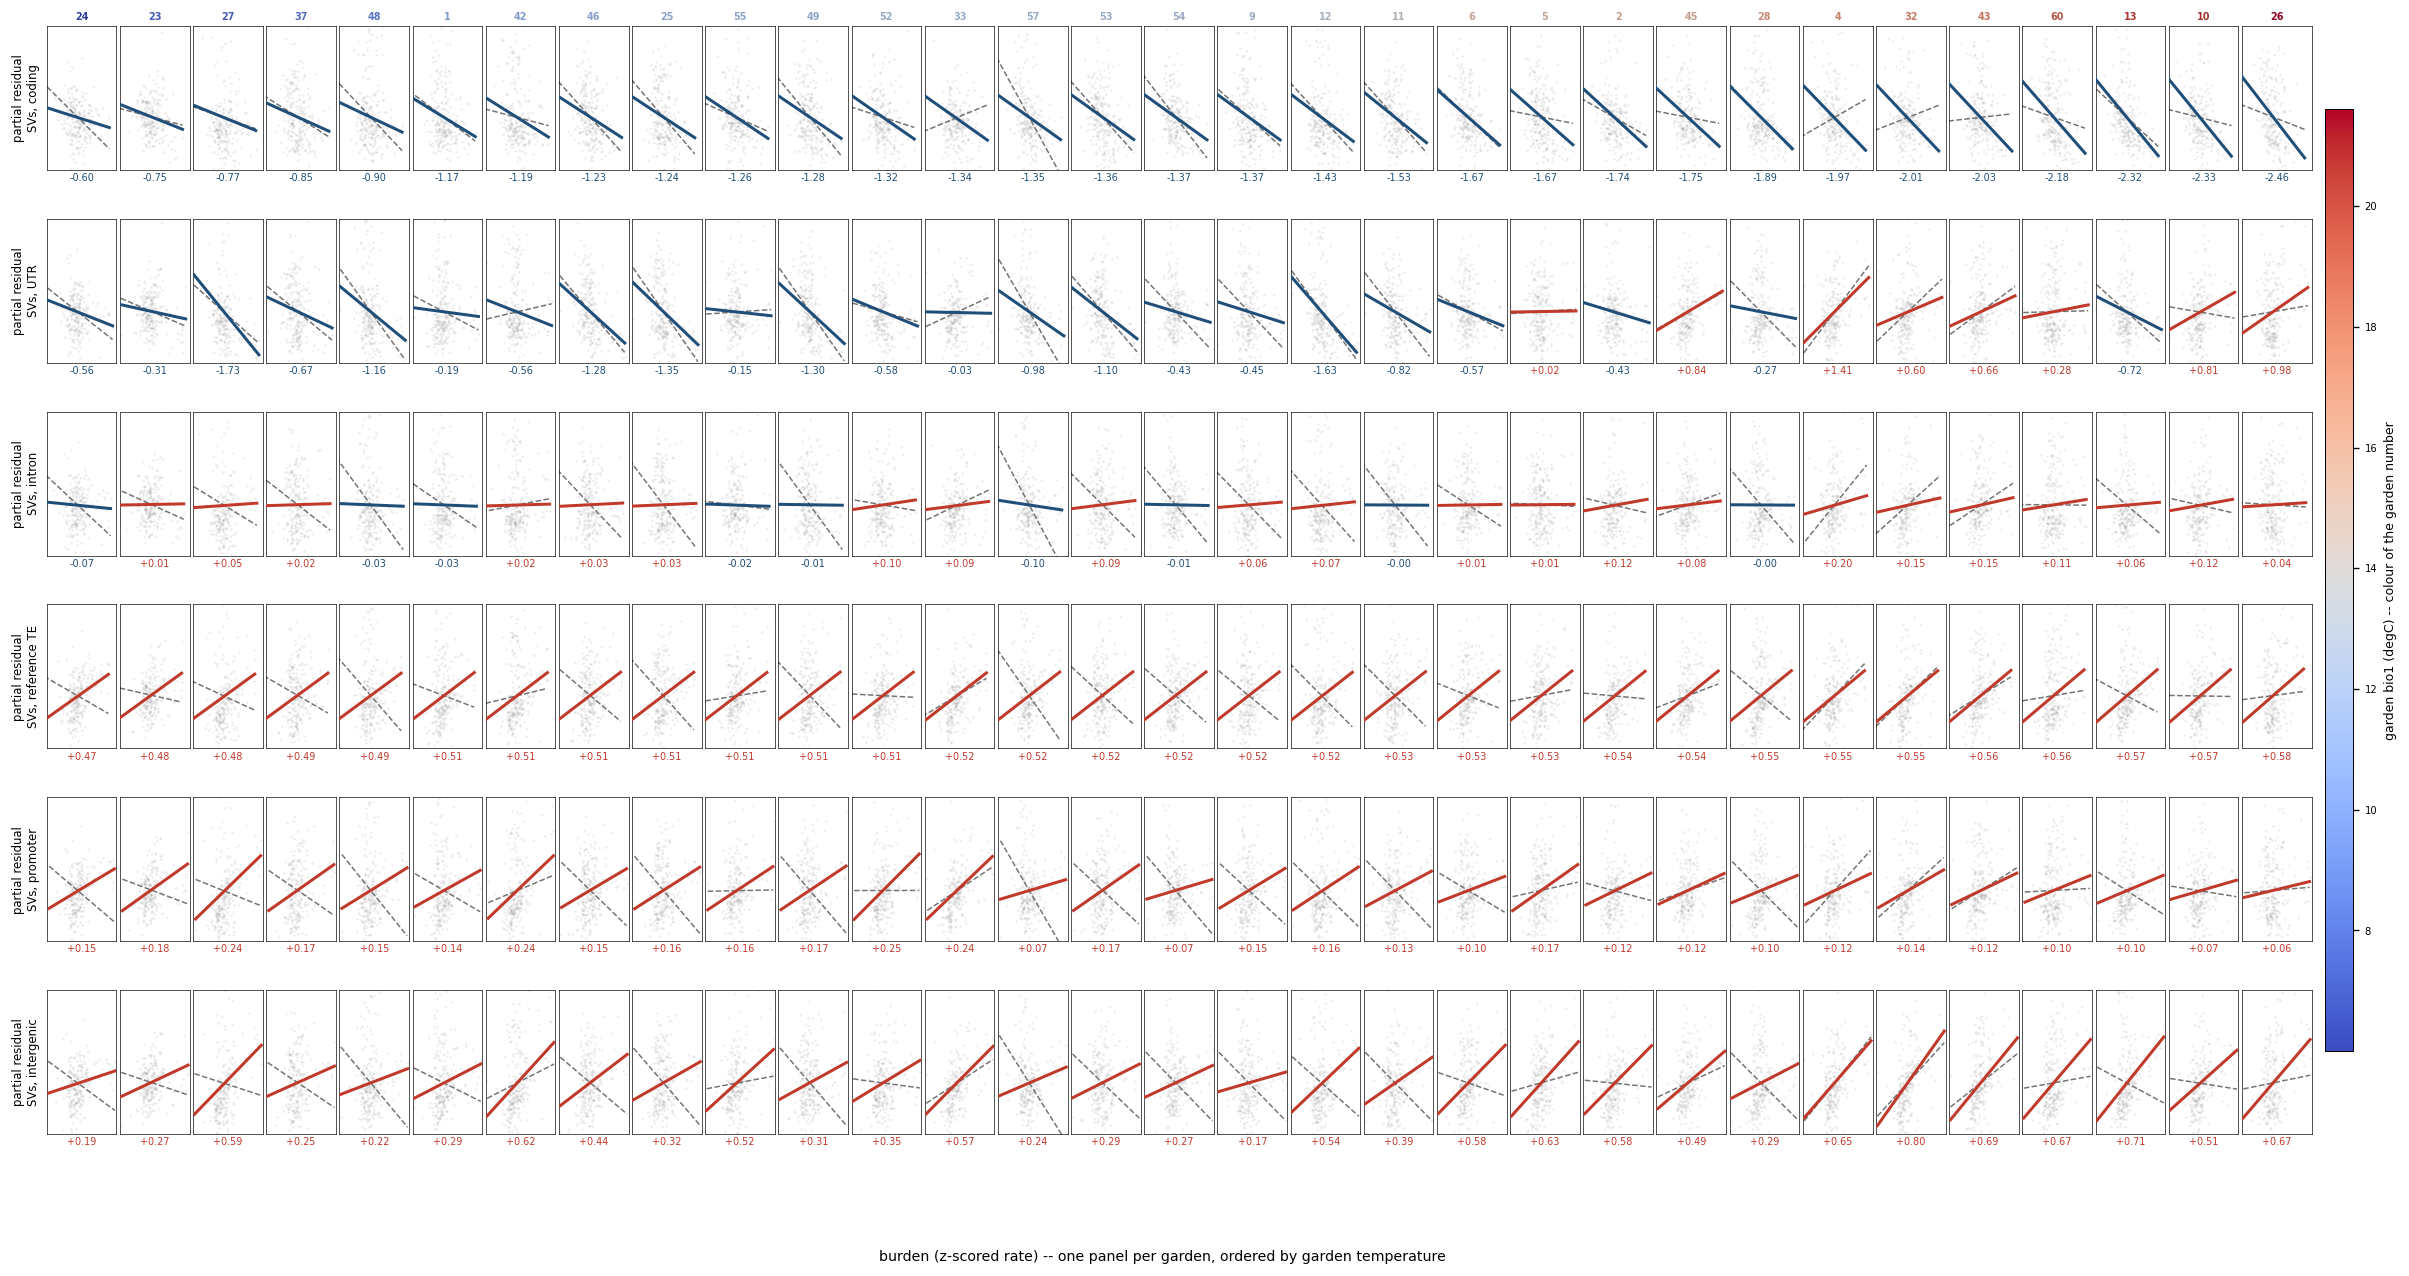

per-garden CONDITIONAL slope (full model) vs RAW within-garden slope, % per carried variant

SVs, coding        conditional -2.46..-0.60, positive in  0/31   |   raw -3.48..+1.09, positive in  4/31   |   r(raw, conditional) = -0.31
SVs, UTR           conditional -1.73..+1.41, positive in  8/31   |   raw -2.43..+1.89, positive in 10/31   |   r(raw, conditional) = +0.85
SVs, intron        conditional -0.10..+0.20, positive in 22/31   |   raw -1.26..+0.83, positive in  6/31   |   r(raw, conditional) = +0.73
SVs, reference TE  conditional +0.47..+0.58, positive in 31/31   |   raw -0.96..+0.71, positive in 10/31   |   r(raw, conditional) = +0.43
SVs, promoter      conditional +0.06..+0.25, positive in 31/31   |   raw -0.43..+0.27, positive in 11/31   |   r(raw, conditional) = +0.19


SVs, intergenic    conditional +0.17..+0.80, positive in 31/31   |   raw -0.90..+0.71, positive in 10/31   |   r(raw, conditional) = +0.77


In [9]:

RS=pd.read_csv(f"{PA}/resid_M2p_reml{SUF}.csv",dtype={"founder":str,"garden":str})
GDX=GD; TT=SVT; LBP={t:LAB2(t) for t in SVT}
gb=GDX.drop_duplicates("garden")[["garden","bio1"]].copy(); gb["garden"]=gb.garden.astype(str)
order=gb.sort_values("bio1").garden.to_list(); bio=dict(zip(gb.garden,gb.bio1))
NORM=mpl.colors.Normalize(min(bio.values()),max(bio.values())); CM=plt.get_cmap("coolwarm")
NEGC,POSC="#1F4E79","#C0392B"                      # negative slope / positive slope
fig,axs=plt.subplots(len(TT),len(order),figsize=(0.80*len(order),2.0*len(TT)),
                     sharex=True,sharey="row",gridspec_kw=dict(hspace=0.34,wspace=0.05))
axs=np.atleast_2d(axs)
for ri,T in enumerate(TT):
    sc=PV(T); tot={str(r.garden):r.total for r in GDX[GDX.term==T].itertuples()}
    pr=RS.resid+RS.garden.map(tot).to_numpy()*RS[T].to_numpy()      # component + residual
    ylo,yhi=np.percentile(pr,[1,99]); xlo,xhi=RS[T].min(),RS[T].max()
    for ci,gname in enumerate(order):
        a=axs[ri,ci]; m=(RS.garden==gname).to_numpy()
        x=RS[T].to_numpy()[m]; yv=pr.to_numpy()[m]
        lc=NEGC if tot[gname]<0 else POSC                # the line is coloured by the SIGN of the slope
        a.scatter(x,yv,s=2.2,color="0.45",alpha=0.13,linewidth=0,rasterized=True)
        xx=np.array([x.min(),x.max()])
        a.plot(xx,tot[gname]*(xx-x.mean())+yv.mean(),color=lc,lw=1.8,zorder=3)
        rw=np.polyfit(x,RS.y.to_numpy()[m],1)[0]                    # raw, nothing controlled
        a.plot(xx,rw*(xx-x.mean())+yv.mean(),color="0.45",lw=0.9,ls="--",zorder=2)
        b=sc*tot[gname]
        a.annotate(f"{b:+.2f}",xy=(0.5,-0.02),xycoords="axes fraction",ha="center",va="top",
                   fontsize=5.8,color=lc)
        a.set_ylim(ylo,yhi); a.set_xlim(xlo-0.15,xhi+0.15)
        a.set_xticks([]); a.set_yticks([]); [sp.set_linewidth(0.4) for sp in a.spines.values()]
        if ri==0: a.annotate(gname,xy=(0.5,1.04),xycoords="axes fraction",ha="center",fontsize=5.8,
                             color=tuple(0.80*np.array(CM(NORM(bio[gname]))[:3])),weight="bold")
        if ci==0: a.set_ylabel(f"partial residual\n{LBP[T]}",fontsize=7)
fig.supxlabel("burden (z-scored rate) -- one panel per garden, ordered by garden temperature",
              fontsize=8.5,y=0.02)
cb=fig.colorbar(mpl.cm.ScalarMappable(norm=NORM,cmap=CM),ax=axs,pad=0.006,fraction=0.012,aspect=34)
cb.set_label("garden bio1 (degC) -- colour of the garden number",fontsize=7.5)
cb.ax.tick_params(labelsize=6)
save(fig,"model_per_garden_panels",nb=True); plt.show()
print("per-garden CONDITIONAL slope (full model) vs RAW within-garden slope, % per carried variant\n")
for T in TT:
    sc=PV(T); tot={str(r.garden):r.total for r in GDX[GDX.term==T].itertuples()}
    rw=np.array([sc*np.polyfit(RS[T].to_numpy()[(RS.garden==g).to_numpy()],
                               RS.y.to_numpy()[(RS.garden==g).to_numpy()],1)[0] for g in order])
    cd=np.array([sc*tot[g] for g in order])
    print(f"{LBP[T]:18s} conditional {cd.min():+.2f}..{cd.max():+.2f}, positive in {(cd>0).sum():2d}/{len(order)}"
          f"   |   raw {rw.min():+.2f}..{rw.max():+.2f}, positive in {(rw>0).sum():2d}/{len(order)}"
          f"   |   r(raw, conditional) = {np.corrcoef(rw,cd)[0,1]:+.2f}")


## 6 · Frequency strata — is the effect carried by rare variants?

Purifying selection predicts that variants are rare *because* they are deleterious, so a coding-SV burden
split by allele frequency should be more damaging in the rare stratum. Frequency is ALT-carrier count over
the full 231-founder panel, a property of the variant.

Bins are **rare** (MAC 2–12, ≤ 5.2 % of the panel) and **common** (MAC 13+), fitted on all 231 founders.
The bottom row, in orange, is the **unstratified** coding-SV coefficient with its own 95 % CI — where the
effect falls when the two strata are held together — and the shaded band carries that interval across the
panel, so each stratum can be read against the undivided estimate rather than only against its point value.

⚠ **Private variants (MAC 1) are excluded.** A variant carried by exactly one founder can only be detected
in a founder that has its own assembly: cactus founders carry a median 52 private events against 3 for
short-read (17×, p = 2 × 10⁻³³), 98 of 151 short-read founders carry **zero** private coding events, and
assembly route alone explains 37 % of the variance in the private burden rate. A three-bin fit restricted
to the 80 cactus founders, where detection is homogeneous, is in the model registry; it is not shown here
because n = 80, the fit is singular, and the private bin still behaves like a detection measure.

⚠ The test is the **contrast**, not two separate p-values. "Rare is significant, common is not" is a
difference in significance, not a significant difference.

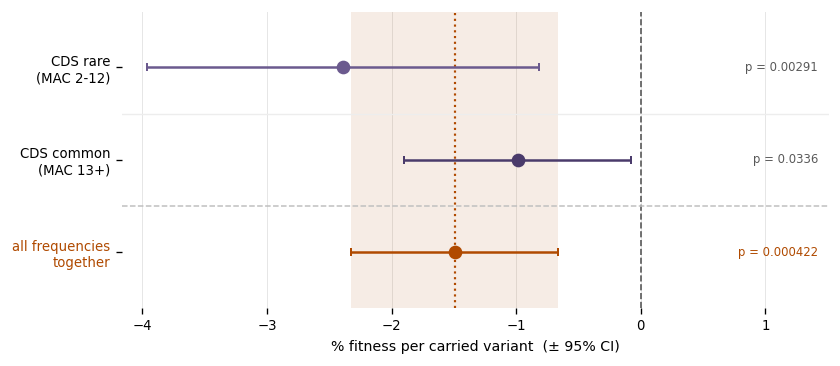

FREQUENCY-STRATIFIED CDS BURDEN, all 231 founders

   bin %/carried variant           95% CI   Wald p median carried total load
  rare           -2.3925 [-3.968, -0.817] 0.002911             17     -40.7%
common           -0.9875 [-1.899, -0.077]  0.03361            132    -130.4%

all frequencies together (unstratified): -1.4945%  [-2.325, -0.664]  p = 0.000422

CONTRAST rare vs common (per carried variant): difference -1.4050   z = -1.64   p = 0.1016

Rare coding SVs are ~2.6x more deleterious per variant than common ones -- the predicted direction --
but the contrast is NOT significant, and common variants carry ~3x more of the TOTAL load because
founders carry far more of them. Both statements are true and answer different questions.


In [10]:

FQ=f"{PA}/coef_M2p_reml_x_obio1cobio1cbio1ccallratesv_re0obio1cgarden_all6_refid_freqCDSrarecommon_intall.csv"
def fload(coefp,scalep,vcovp):
    co=pd.read_csv(coefp).set_index("term"); sc=pd.read_csv(scalep).set_index("context")
    pv={f"sv_{c}":100/(sc.loc[c,"sd_rate"]*sc.loc[c,"med_called"]) for c in sc.index}
    return co,pv,sc,pd.read_csv(vcovp,index_col=0)
co,pv,sc,V=fload(FQ,f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1ccallratesv_all6_freqCDSrarecommon.csv",
                 FQ.replace("coef_","vcov_"))
def contrast(co,pv,V,a,b):
    ka,kb=pv[a],pv[b]
    d=co.loc[a,"estimate"]*ka-co.loc[b,"estimate"]*kb
    v=V.loc[a,a]*ka**2+V.loc[b,b]*kb**2-2*V.loc[a,b]*ka*kb
    z=d/np.sqrt(v); return d,z,2*stats.norm.sf(abs(z))
# the undivided coding-SV effect, with its interval, so the strata can be compared against the whole
UNS=CO.loc["sv_CDS","estimate"]*PV("sv_CDS")
UNSE=CO.loc["sv_CDS","se"]*PV("sv_CDS")
UNLO,UNHI=UNS-1.96*UNSE,UNS+1.96*UNSE
BINS=["rare","common"]; FC={"rare":"#6B5A8E","common":"#4A3B6B"}
fig,a=plt.subplots(figsize=(7.6,3.2)); style(a); a.axvline(0,color="0.35",lw=1,ls="--")
a.axvspan(UNLO,UNHI,color="#B04A00",alpha=0.10,lw=0,zorder=1)     # 95% CI of the undivided estimate
a.axvline(UNS,color="#B04A00",lw=1.3,ls=":",zorder=2)
for i,b in enumerate(BINS):
    t=f"sv_CDS_{b}"; e=co.loc[t,"estimate"]*pv[t]; se=co.loc[t,"se"]*pv[t]
    a.errorbar(e,i,xerr=1.96*se,fmt="o",color=FC[b],mfc=FC[b] if co.loc[t,"p"]<0.05 else "white",
               mew=1.2,ms=7,capsize=2.5,zorder=3)
    a.annotate(f"p = {co.loc[t,'p']:.3g}",xy=(0.985,i),xycoords=("axes fraction","data"),
               ha="right",va="center",fontsize=7,color="0.35")
    if i<len(BINS)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.axhline(len(BINS)-0.5,color="0.75",lw=0.9,ls="--")               # separator: strata above, whole below
a.errorbar(UNS,len(BINS),xerr=1.96*UNSE,fmt="o",color="#B04A00",mew=1.2,ms=7,capsize=2.5,zorder=3)
a.annotate(f"p = {CO.loc['sv_CDS','p']:.3g}",xy=(0.985,len(BINS)),xycoords=("axes fraction","data"),
           ha="right",va="center",fontsize=7,color="#B04A00")
a.set_yticks(range(len(BINS)+1))
a.set_yticklabels(["CDS rare\n(MAC 2-12)","CDS common\n(MAC 13+)","all frequencies\ntogether"],fontsize=8)
a.get_yticklabels()[-1].set_color("#B04A00")
a.invert_yaxis(); a.set_ylim(len(BINS)+0.6,-0.6)
x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.30*(x1-x0))
a.set_xlabel("% fitness per carried variant  (± 95% CI)",fontsize=8.5)
save(fig,"model_freq_strata",nb=True); plt.show()
print("FREQUENCY-STRATIFIED CDS BURDEN, all 231 founders\n")
print(pd.DataFrame([{"bin":b,
    "%/carried variant":f"{co.loc[f'sv_CDS_{b}','estimate']*pv[f'sv_CDS_{b}']:+.4f}",
    "95% CI":f"[{(co.loc[f'sv_CDS_{b}','estimate']-1.96*co.loc[f'sv_CDS_{b}','se'])*pv[f'sv_CDS_{b}']:+.3f}, "
             f"{(co.loc[f'sv_CDS_{b}','estimate']+1.96*co.loc[f'sv_CDS_{b}','se'])*pv[f'sv_CDS_{b}']:+.3f}]",
    "Wald p":f"{co.loc[f'sv_CDS_{b}','p']:.4g}",
    "median carried":f"{sc.loc[f'CDS_{b}','med_carried']:.0f}",
    "total load":f"{co.loc[f'sv_CDS_{b}','estimate']*pv[f'sv_CDS_{b}']*sc.loc[f'CDS_{b}','med_carried']:+.1f}%"}
    for b in BINS]).to_string(index=False))
print(f"\nall frequencies together (unstratified): {UNS:+.4f}%  [{UNLO:+.3f}, {UNHI:+.3f}]  "
      f"p = {CO.loc['sv_CDS','p']:.4g}")
d,z,p=contrast(co,pv,V,"sv_CDS_rare","sv_CDS_common")
print(f"\nCONTRAST rare vs common (per carried variant): difference {d:+.4f}   z = {z:+.2f}   p = {p:.4g}")
print("\nRare coding SVs are ~2.6x more deleterious per variant than common ones -- the predicted direction --")
print("but the contrast is NOT significant, and common variants carry ~3x more of the TOTAL load because")
print("founders carry far more of them. Both statements are true and answer different questions.")


## 7 · Size strata — is the effect carried by large SVs?

The same question along the other axis. Insertions and deletions stay **pooled**: which one a variant is
called depends on the Col-0 reference and is not a biological distinction — the same reason the
site-frequency spectra in Figure 1 are folded.

Bins are 50–99 / 100–499 / 500+ bp, the most balanced three-way split available in CDS (444 / 481 / 482
events). MAC ≥ 2 throughout, matching the model, so the singleton class cannot leak in. As in §7 the bottom
row and shaded band are the **unstratified** coefficient and its 95 % CI — where the effect falls with all
sizes held together.

⚠ Size is partly a proxy for insertion vs deletion at the *event* level — the largest CDS bin is 80 %
insertions, the smallest 38 %, because CDS insertions are ~3× larger here. At the *carried* level, which is
what the burden counts, every bin is 50–53 % insertions, so pooling is not hiding a class contrast.

Because three bins each hold a third of the variants, each is far less precise than the undivided term. The
cell therefore reports an **omnibus test** of whether the bins differ at all, and a **power calculation** —
both needed to read "only the large bin is significant" correctly.

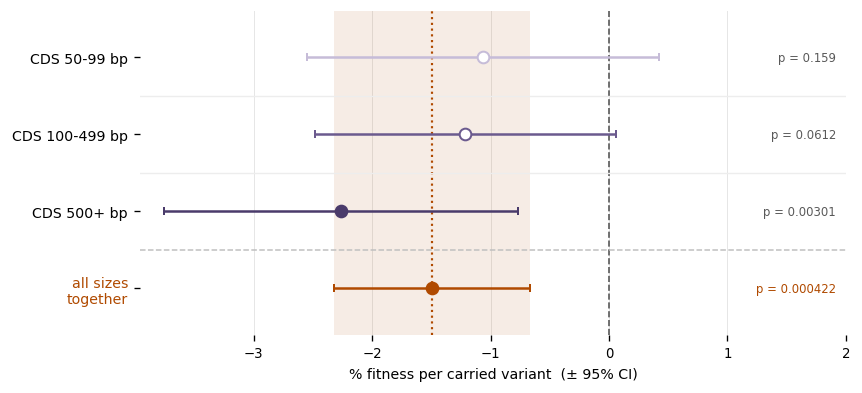

SIZE-STRATIFIED CDS BURDEN (pooled ins+del, MAC>=2)

   bin      range %/carried variant           95% CI   Wald p median carried
 small   50-99 bp           -1.0682 [-2.555, +0.419]   0.1591             44
medium 100-499 bp           -1.2134 [-2.484, +0.057]  0.06125             49
 large    500+ bp           -2.2615 [-3.755, -0.768] 0.003005             56

all sizes together (unstratified): -1.4945%  [-2.325, -0.664]  p = 0.000422

CONTRASTS (per carried variant):
  small   vs medium  difference +0.1452   z = +0.15   p = 0.8786
  medium  vs large   difference +1.0481   z = +1.04   p = 0.2987
  small   vs large   difference +1.1933   z = +1.14   p = 0.2551

OMNIBUS TEST -- do the three bins differ at all?  chi2 = 1.518 on 2 df, p = 0.4682

POWER -- if all three bins truly had the unstratified effect, how often would each
         individually reach p < 0.05?
  small   SE 0.759  ->  power 50%
  medium  SE 0.648  ->  power 64%
  large   SE 0.762  ->  power 50%
  expected number of bins

In [11]:

SZ=f"{PA}/coef_M2p_reml_x_obio1cobio1cbio1c_re0obio1cgarden_all6_refid_freqCDSsmallmediumlarge_intall.csv"
co,pv,sc,V=fload(SZ,f"{PA}/pooled_rate_scale_x_obio1cobio1cbio1c_all6_freqCDSsmallmediumlarge.csv",
                 SZ.replace("coef_","vcov_"))
BINS=["small","medium","large"]; SC3={"small":"#C6BCD8","medium":"#6B5A8E","large":"#4A3B6B"}
RNG={"small":"50-99 bp","medium":"100-499 bp","large":"500+ bp"}
e=np.array([co.loc[f"sv_CDS_{b}","estimate"]*pv[f"sv_CDS_{b}"] for b in BINS])
se=np.array([co.loc[f"sv_CDS_{b}","se"]*pv[f"sv_CDS_{b}"] for b in BINS])
fig,a=plt.subplots(figsize=(7.6,3.5)); style(a); a.axvline(0,color="0.35",lw=1,ls="--")
a.axvspan(UNLO,UNHI,color="#B04A00",alpha=0.10,lw=0,zorder=1)     # 95% CI of the undivided estimate
a.axvline(UNS,color="#B04A00",lw=1.3,ls=":",zorder=2)
for i,b in enumerate(BINS):
    t=f"sv_CDS_{b}"
    a.errorbar(e[i],i,xerr=1.96*se[i],fmt="o",color=SC3[b],mfc=SC3[b] if co.loc[t,"p"]<0.05 else "white",
               mew=1.2,ms=7,capsize=2.5,zorder=3)
    a.annotate(f"p = {co.loc[t,'p']:.3g}",xy=(0.985,i),xycoords=("axes fraction","data"),
               ha="right",va="center",fontsize=7,color="0.35")
    if i<len(BINS)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
a.axhline(2.5,color="0.75",lw=0.9,ls="--")                        # separator: strata above, whole below
a.errorbar(UNS,3,xerr=1.96*UNSE,fmt="o",color="#B04A00",mew=1.2,ms=7,capsize=2.5,zorder=3)
a.annotate(f"p = {CO.loc['sv_CDS','p']:.3g}",xy=(0.985,3),xycoords=("axes fraction","data"),
           ha="right",va="center",fontsize=7,color="#B04A00")
a.set_yticks(range(4)); a.set_yticklabels([f"CDS {RNG[b]}" for b in BINS]+["all sizes\ntogether"],fontsize=8.5)
a.get_yticklabels()[-1].set_color("#B04A00")
a.invert_yaxis(); a.set_ylim(3.6,-0.6)
x0,x1=a.get_xlim(); a.set_xlim(x0,x1+0.30*(x1-x0))
a.set_xlabel("% fitness per carried variant  (± 95% CI)",fontsize=8.5)
save(fig,"model_size_strata",nb=True); plt.show()
print("SIZE-STRATIFIED CDS BURDEN (pooled ins+del, MAC>=2)\n")
print(pd.DataFrame([{"bin":b,"range":RNG[b],"%/carried variant":f"{e[i]:+.4f}",
    "95% CI":f"[{e[i]-1.96*se[i]:+.3f}, {e[i]+1.96*se[i]:+.3f}]",
    "Wald p":f"{co.loc[f'sv_CDS_{b}','p']:.4g}",
    "median carried":f"{sc.loc[f'CDS_{b}','med_carried']:.0f}"} for i,b in enumerate(BINS)]
    ).to_string(index=False))
print(f"\nall sizes together (unstratified): {UNS:+.4f}%  [{UNLO:+.3f}, {UNHI:+.3f}]  "
      f"p = {CO.loc['sv_CDS','p']:.4g}")
print("\nCONTRASTS (per carried variant):")
for a_,b_ in (("small","medium"),("medium","large"),("small","large")):
    d,z,p=contrast(co,pv,V,f"sv_CDS_{a_}",f"sv_CDS_{b_}")
    print(f"  {a_:<7} vs {b_:<7} difference {d:+.4f}   z = {z:+.2f}   p = {p:.4g}")
k=np.array([pv[f"sv_CDS_{b}"] for b in BINS]); T3=[f"sv_CDS_{b}" for b in BINS]
Vs=V.loc[T3,T3].to_numpy()*np.outer(k,k); Lc=np.array([[1,-1,0],[0,1,-1]])
dd=Lc@e; W=dd@np.linalg.solve(Lc@Vs@Lc.T,dd)
print(f"\nOMNIBUS TEST -- do the three bins differ at all?  chi2 = {W:.3f} on 2 df, p = {stats.chi2.sf(W,2):.4g}")
print("\nPOWER -- if all three bins truly had the unstratified effect, how often would each")
print("         individually reach p < 0.05?")
pw=[stats.norm.sf(1.96-abs(UNS)/s)+stats.norm.cdf(-1.96-abs(UNS)/s) for s in se]
for b,s,w in zip(BINS,se,pw): print(f"  {b:<7} SE {s:.3f}  ->  power {w:.0%}")
print(f"  expected number of bins reaching p<0.05 under that null: {sum(pw):.1f} of 3 -- and 1 was observed.")
print("\nEvery bin's CI contains the other bins' point estimates and the unstratified value, the omnibus")
print("test is far from significant, and one-of-three significant is the EXPECTED outcome even if size is")
print("irrelevant. The estimates order as theory predicts, but the study cannot resolve them.")


## 8 · The relationship, raw and adjusted

**(a) Raw.** Each founder's mean log-fitness across the 31 gardens against the number of coding SV events
it carries. No adjustment at all — no kinship, no other burdens, no assembly route. This is the picture in
its most literal form.

**(b) Added-variable plot.** The statistically correct version: both axes residualised on every other
predictor *and* on kinship, in the model's own GLS metric. The slope of this plot **is** the model's
coefficient — the cell checks that identity rather than asserting it. Panel (a) is raw and unadjusted; its
correlation is therefore not the model's estimate, panel (b)'s slope is.

The shape to look for: a diffuse cloud sloping down means a broad population tendency; a tight cluster
plus a few far-flung points means a handful of founders are setting the slope.

In [12]:
import numpy as np
from scipy import linalg
GG=f"{G}/final_models_pooled_all"; SUF="_x_obio1cobio1cbio1c_re0obio1cgarden_all6_refid_intall"
CTX=["CDS","UTR","intron","TE","promoter","intergenic"]
TERMS=["snp_CDS","sv_CDS","sv_UTR","sv_intron","sv_TE","sv_promoter","sv_intergenic","cactus","obio1c"]
J=TERMS.index("sv_CDS")+1                                  # +1 for the intercept column
CC="#4A3B6B"                                               # sv_CDS keeps its colour from the pooled figures

L=pd.read_csv(f"{G}/onestage_all/long.csv",dtype={"founder":str})
K=pd.read_csv(f"{G}/onestage_all/kinship.csv",index_col=0)
K.index=K.index.astype(str); K.columns=K.columns.astype(str)
B=pd.read_csv(f"{G}/founder_burden_event.csv",dtype={"founder":str})
zz=lambda v:(v-v.mean())/v.std(ddof=1)
P=pd.DataFrame({"founder":B.founder})
for c in CTX:
    P[f"sv_{c}"]=zz((B[f"ins_all_{c}_all"]+B[f"del_all_{c}_all"])
                    /(B[f"called_ins_all_{c}_all"]+B[f"called_del_all_{c}_all"]))
P["obio1c"]=B.bio1-B.bio1.mean()
P=P.merge(L.drop_duplicates("founder")[["founder","snp_CDS","cactus"]],on="founder")
P=P.merge(B[["founder","is_cactus"]],on="founder")
P["carried_CDS"]=(B.ins_all_CDS_all+B.del_all_CDS_all).to_numpy()
D=P.merge(L.groupby("founder").y.mean().rename("ybar").reset_index(),on="founder").set_index("founder")
n_g=L.garden.nunique(); fo=D.index.to_list()

vc=pd.read_csv(f"{GG}/varcomp_M2p_reml{SUF}.csv")
gv=lambda g: float(vc[vc.grp==g].vcov.iloc[0]) if (vc.grp==g).any() else 0.0
# variance of a founder MEAN over n_g gardens: the kinship term is unchanged, the independent founder
# term is unchanged (0 here -- the reported fit prunes it), and the residual is divided by the number of
# gardens averaged over. The random garden slopes, local adaptation's included, contribute rank-1 terms
# proportional to columns of X; GLS is invariant to variance components lying in the column space of X
# (Zyskind's condition), so they drop out and the reduction stays exact -- the validation below checks it.
V=gv("kin")*K.loc[fo,fo].to_numpy()+(gv("fid")+gv("Residual")/n_g)*np.eye(len(D))
Vi=np.linalg.inv(V)
X=np.column_stack([np.ones(len(D))]+[D[c].to_numpy(float) for c in TERMS])
y=D.ybar.to_numpy(float)
def gls(Xm,ym,Vim):
    A=Xm.T@Vim@Xm; b=np.linalg.solve(A,Xm.T@Vim@ym); return b,np.sqrt(np.diag(np.linalg.inv(A)))
b0,se0=gls(X,y,Vi); p0=2*stats.norm.sf(abs(b0[J]/se0[J]))
LMM=pd.read_csv(f"{GG}/coef_M2p_reml{SUF}.csv").set_index("term")
print(f"{len(D)} founders x {n_g} gardens; variance components taken from the fitted LMM:")
print(f"  kin {gv('kin'):.5f}   fid {gv('fid'):.5f}   residual {gv('Residual'):.5f}\n")
print("VALIDATION — founder-mean GLS against the fitted mixed model:")
rows=[]
for i,nm in enumerate(["(Intercept)"]+TERMS):
    if nm in LMM.index:
        rows.append({"term":nm,"GLS estimate":f"{b0[i]:+.5f}","LMM estimate":f"{LMM.loc[nm,'estimate']:+.5f}",
                     "abs diff":f"{abs(b0[i]-LMM.loc[nm,'estimate']):.2e}"})
print(pd.DataFrame(rows).to_string(index=False))
mx=max(abs(b0[i]-LMM.loc[nm,"estimate"]) for i,nm in enumerate(["(Intercept)"]+TERMS) if nm in LMM.index)
print(f"\nlargest discrepancy across all main effects: {mx:.2e}  -> the reduction is exact")
print(f"\nsv_CDS in the reduced model: {b0[J]:+.5f} +- {se0[J]:.5f}   p = {p0:.4g}")


231 founders x 31 gardens; variance components taken from the fitted LMM:
  kin 0.25337   fid 0.00000   residual 1.15105

VALIDATION — founder-mean GLS against the fitted mixed model:
         term GLS estimate LMM estimate abs diff
  (Intercept)     -1.21525     -1.21525 8.68e-14
      snp_CDS     -0.46868     -0.46868 1.55e-13
       sv_CDS     -0.28644     -0.28644 9.98e-14
       sv_UTR     -0.09530     -0.09530 4.90e-14
    sv_intron     +0.02267     +0.02267 4.82e-14
        sv_TE     +0.28226     +0.28226 2.16e-13
  sv_promoter     +0.20674     +0.20674 6.08e-13
sv_intergenic     +0.28776     +0.28776 6.26e-14
       cactus     -0.00900     -0.00900 3.00e-13
       obio1c     +0.02193     +0.02193 3.07e-14

largest discrepancy across all main effects: 6.08e-13  -> the reduction is exact

sv_CDS in the reduced model: -0.28644 +- 0.08124   p = 0.000422


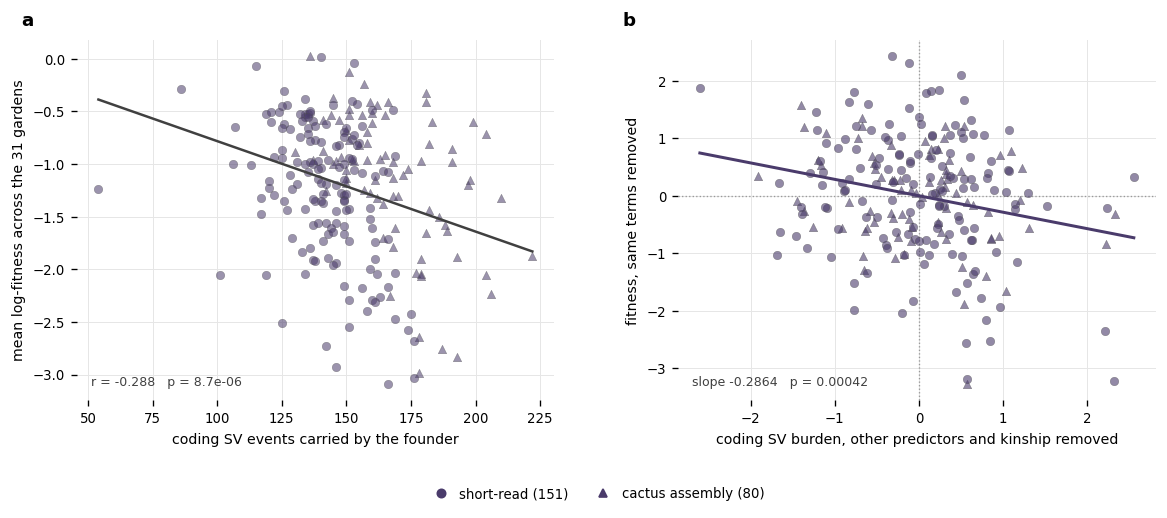

added-variable slope -0.286438   model coefficient -0.286438   identical: True
raw correlation (no adjustment):        r = -0.288  p = 8.68e-06
carried coding SV events per founder:   median 149  range 54-222


In [13]:
W=linalg.sqrtm(Vi).real; Xw=W@X; yw=W@y               # whiten, so the AVP is in the metric the model fits in
Xo=np.delete(Xw,J,axis=1)
rx=Xw[:,J]-Xo@np.linalg.lstsq(Xo,Xw[:,J],rcond=None)[0]
ry=yw      -Xo@np.linalg.lstsq(Xo,yw     ,rcond=None)[0]
slope=(rx@ry)/(rx@rx)
D["rx"]=rx; D["ry"]=ry
cac=(D.is_cactus.astype(str)=="True").to_numpy()
fig,axs=plt.subplots(1,2,figsize=(11.6,3.9),gridspec_kw=dict(wspace=0.26))
a=axs[0]; style(a,axis="both"); panel(a,"a",x=-0.09)
for m,mk in ((cac,"^"),(~cac,"o")):
    a.scatter(D.carried_CDS[m],D.ybar[m],s=26,marker=mk,color=CC,alpha=0.55,linewidth=0.3,edgecolor="0.3",zorder=3)
xx=np.linspace(D.carried_CDS.min(),D.carried_CDS.max(),50)
a.plot(xx,np.polyval(np.polyfit(D.carried_CDS,D.ybar,1),xx),color="0.25",lw=1.5,zorder=4)
r_,p_=stats.pearsonr(D.carried_CDS,D.ybar)
a.annotate(f"r = {r_:+.3f}   p = {p_:.2g}",xy=(0.03,0.04),xycoords="axes fraction",
           fontsize=7.5,color="0.25")
a.set_xlabel("coding SV events carried by the founder",fontsize=8.5)
a.set_ylabel("mean log-fitness across the 31 gardens",fontsize=8.5)
a=axs[1]; style(a,axis="both"); panel(a,"b",x=-0.09)
for m,mk in ((cac,"^"),(~cac,"o")):
    a.scatter(D.rx[m],D.ry[m],s=26,marker=mk,color=CC,alpha=0.6,linewidth=0.3,edgecolor="0.3",zorder=3)
xx=np.linspace(D.rx.min(),D.rx.max(),50); a.plot(xx,b0[J]*xx,color=CC,lw=1.8,zorder=4)
a.axhline(0,color="0.6",lw=0.8,ls=":"); a.axvline(0,color="0.6",lw=0.8,ls=":")
a.annotate(f"slope {b0[J]:+.4f}   p = {p0:.2g}",xy=(0.03,0.04),
           xycoords="axes fraction",fontsize=7.5,color="0.25")
a.set_xlabel("coding SV burden, other predictors and kinship removed",fontsize=8.5)
a.set_ylabel("fitness, same terms removed",fontsize=8.5)
h=[plt.Line2D([],[],marker=m,color=CC,ls="none",ms=5) for m in ("o","^")]
fig.legend(h,[f"short-read ({int((~cac).sum())})",f"cactus assembly ({int(cac.sum())})"],
           loc="lower center",bbox_to_anchor=(0.5,-0.13),ncol=2,fontsize=8,handlelength=1.2)
save(fig,"cds_influence_scatter",nb=True); plt.show()
print(f"added-variable slope {slope:+.6f}   model coefficient {b0[J]:+.6f}   identical: {np.isclose(slope,b0[J])}")
print(f"raw correlation (no adjustment):        r = {r_:+.3f}  p = {p_:.3g}")
print(f"carried coding SV events per founder:   median {D.carried_CDS.median():.0f}  "
      f"range {D.carried_CDS.min():.0f}-{D.carried_CDS.max():.0f}")


## 9 · Jackknife — refit 231 times, dropping one ecotype each time

The committee's question directly: how stable is the coefficient when ecotypes are removed?

Each of the 231 refits leaves out one founder and re-estimates `sv_CDS`. **The y-axis is the coefficient
itself**, not a change or a percentage — so the plot can be read against the two reference lines that
matter: the full-sample estimate, and zero.

The comparison that makes "stable" concrete is the **jackknife spread against the confidence interval**. If
the estimate depended on particular ecotypes, dropping them would move it a large fraction of its own
uncertainty. If no ecotype matters much, all 231 estimates pile up in a band far narrower than the CI, and
all of them sit well away from zero — which is what happens: the 231 refits span a band **22 % as wide as
the CI**, and none comes within **2.9 standard errors** of zero. The figure shows the spread; the numbers
are printed beneath it.



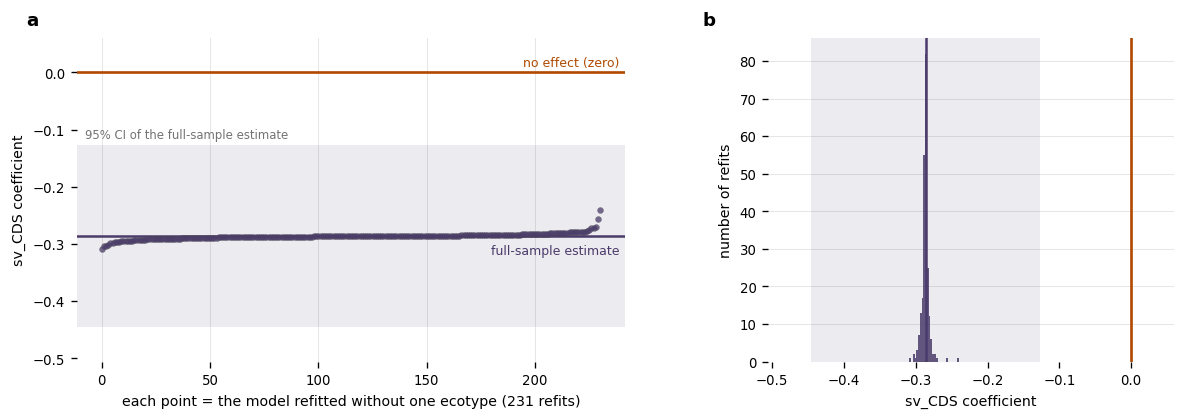

JACKKNIFE — sv_CDS refitted 231 times, leaving out one ecotype each time

  full-sample estimate   -0.28644   95% CI [-0.4457, -0.1272]
  jackknife estimates    min -0.30908   max -0.24026   SD 0.00593
  jackknife range 0.06882 = 22% of the CI width
  all 231 estimates negative: True;  closest to zero -0.24026 = 3.0 SE away

  the single most influential ecotype moves it 0.04618 (16.1% of the coefficient); the median ecotype 0.00188 (0.66%)
  dropping it: -0.28644 -> -0.24026,  p = 0.000422 -> 0.003728

  the six most influential ecotypes:
founder sv_CDS burden (z)  carried mean fitness estimate without it
   9965             +0.41      151       -2.547            -0.24026
  10013             -0.67      119       -2.053            -0.25658
   6180             -5.06       54       -1.236            -0.30908
   7287             +0.68      164       -1.064            -0.30345
   7013             -1.11      129       -1.699            -0.30298
   6961             -1.58      115       -0.07

In [14]:
n=len(y); dfb=np.zeros(n); Vfull=np.linalg.inv(Vi)
for i in range(n):
    m=np.ones(n,bool); m[i]=False
    Vs=np.linalg.inv(Vfull[np.ix_(m,m)])               # condition on dropping founder i, not just delete a row
    dfb[i]=gls(X[m],y[m],Vs)[0][J]-b0[J]
D["dfbeta"]=dfb; loo=b0[J]+dfb                          # the 231 jackknife ESTIMATES, on the coefficient scale
lo,hi=b0[J]-1.96*se0[J],b0[J]+1.96*se0[J]

fig,axs=plt.subplots(1,2,figsize=(11.8,3.5),gridspec_kw=dict(width_ratios=[1.35,1],wspace=0.30))
a=axs[0]; style(a,axis="x"); panel(a,"a",x=-0.07)
a.axhspan(lo,hi,color=CC,alpha=0.10,lw=0)                                  # full-sample 95% CI
a.axhline(b0[J],color=CC,lw=1.5)
a.axhline(0,color="#B04A00",lw=1.6)
o=np.argsort(loo)
a.scatter(np.arange(n),loo[o],s=13,color=CC,alpha=0.75,linewidth=0.2,edgecolor="0.3",zorder=3)
a.set_ylim(min(lo,0)-0.06,max(hi,0)+0.06)
a.set_xlabel("each point = the model refitted without one ecotype (231 refits)",fontsize=8.5)
a.set_ylabel("sv_CDS coefficient",fontsize=8.5)
a.annotate("no effect (zero)",xy=(0.99,0),xycoords=("axes fraction","data"),xytext=(0,4),
           textcoords="offset points",ha="right",fontsize=7.5,color="#B04A00")
a.annotate("full-sample estimate",xy=(0.99,b0[J]),xycoords=("axes fraction","data"),xytext=(0,-11),
           textcoords="offset points",ha="right",fontsize=7.5,color=CC)
a.annotate("95% CI of the full-sample estimate",xy=(0.015,hi),xycoords=("axes fraction","data"),
           xytext=(0,4),textcoords="offset points",fontsize=7,color="0.45")

a=axs[1]; style(a,axis="y"); panel(a,"b",x=-0.13)
a.hist(loo,bins=28,color=CC,alpha=0.85,lw=0)
a.axvline(b0[J],color=CC,lw=1.5); a.axvline(0,color="#B04A00",lw=1.6)
a.axvspan(lo,hi,color=CC,alpha=0.10,lw=0)
a.set_xlim(min(lo,0)-0.06,max(hi,0)+0.06)
a.set_xlabel("sv_CDS coefficient",fontsize=8.5); a.set_ylabel("number of refits",fontsize=8.5)
save(fig,"cds_influence_jackknife",nb=True); plt.show()

print(f"JACKKNIFE — sv_CDS refitted 231 times, leaving out one ecotype each time\n")
print(f"  full-sample estimate   {b0[J]:+.5f}   95% CI [{lo:+.4f}, {hi:+.4f}]")
print(f"  jackknife estimates    min {loo.min():+.5f}   max {loo.max():+.5f}   SD {loo.std(ddof=1):.5f}")
print(f"  jackknife range {loo.max()-loo.min():.5f} = {(loo.max()-loo.min())/(hi-lo):.0%} of the CI width")
print(f"  all {n} estimates negative: {bool((loo<0).all())};  "
      f"closest to zero {loo.max():+.5f} = {abs(loo.max())/se0[J]:.1f} SE away")
print(f"\n  the single most influential ecotype moves it {abs(dfb).max():.5f} "
      f"({100*abs(dfb).max()/abs(b0[J]):.1f}% of the coefficient); the median ecotype "
      f"{np.median(abs(dfb)):.5f} ({100*np.median(abs(dfb))/abs(b0[J]):.2f}%)")
i1=np.argmax(np.abs(dfb)); m=np.ones(n,bool); m[i1]=False
bb,ss=gls(X[m],y[m],np.linalg.inv(Vfull[np.ix_(m,m)]))
print(f"  dropping it: {b0[J]:+.5f} -> {bb[J]:+.5f},  p = {p0:.4g} -> {2*stats.norm.sf(abs(bb[J]/ss[J])):.4g}")
print("\n  the six most influential ecotypes:")
T=D.reindex(np.abs(D.dfbeta).sort_values(ascending=False).index).head(6)
print(pd.DataFrame([{"founder":i,"sv_CDS burden (z)":f"{r.sv_CDS:+.2f}","carried":int(r.carried_CDS),
                     "mean fitness":f"{r.ybar:+.3f}","estimate without it":f"{b0[J]+r.dfbeta:+.5f}"}
                    for i,r in T.iterrows()]).to_string(index=False))


## 10 · Is dropping one ecotype enough? — delete-d subsampling

Leave-one-out answers a narrow question: *is any single ecotype driving this?* It is the standard influence
diagnostic, but it is a gentle perturbation. A fairer stress test drops a **random fraction** of the panel
and refits, many times over.

One trap has to be handled first. Dropping 20 % of ecotypes leaves fewer observations, so the estimate will
scatter more **for that reason alone** — a wider spread is not evidence of instability. The raw spread is
therefore the wrong comparison. The right one is the **delete-d jackknife standard error**, which rescales
the subsample spread back to the full sample size:

```
SE_jack(d)  =  sqrt( (n - d) / d  *  mean_over_subsets( (beta_subset - beta_mean)^2 ) )
```

If the estimate rests on a few ecotypes, this number **grows** as `d` grows: dropping more of the panel
starts hitting the ecotypes that matter. If the effect is spread across the panel, it stays flat and close
to the model's own standard error, whatever fraction you delete. It is printed under each level in the
figure and in the table below — that flatness is the test, not the widening spread above it.

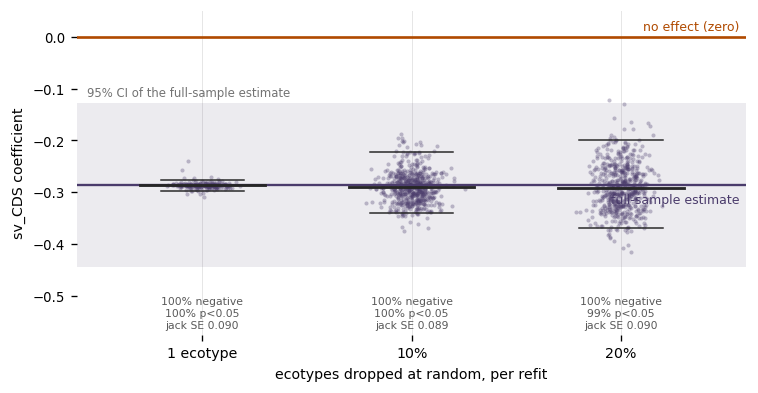

DELETE-d SUBSAMPLING — drop a random fraction of ecotypes, refit, repeat

  dropped  n kept mean estimate      SD    2.5%   97.5% % negative % p<0.05 delete-d jack SE
1 ecotype     230      -0.28660 0.00593 -0.2974 -0.2764     100.0%   100.0%          0.08968
      10%     208      -0.29009 0.02968 -0.3403 -0.2222     100.0%   100.0%          0.08917
      20%     185      -0.29030 0.04495 -0.3697 -0.1997     100.0%    98.8%          0.09006

  model SE for comparison: 0.08124
  delete-d jackknife SE across the three levels: 0.08917 to 0.09006 -- flat,
  so the estimate does not depend on which ecotypes are in the sample.

  At 20% dropped, every one of the 600 refits returns a negative estimate.


In [15]:
rng=np.random.default_rng(0); R=600; Vm=np.linalg.inv(Vi)
LEV=[(1,"1 ecotype"),(int(round(0.10*n)),"10%"),(int(round(0.20*n)),"20%")]
res={}
for d,lab in LEV:
    idx=[np.array([i]) for i in range(n)] if d==1 else [rng.choice(n,d,replace=False) for _ in range(R)]
    bs=[];ps=[]
    for drop in idx:
        m=np.ones(n,bool); m[drop]=False
        bb,ss=gls(X[m],y[m],np.linalg.inv(Vm[np.ix_(m,m)]))
        bs.append(bb[J]); ps.append(2*stats.norm.sf(abs(bb[J]/ss[J])))
    bs=np.array(bs); ps=np.array(ps)
    res[d]=dict(lab=lab,bs=bs,ps=ps,jse=np.sqrt(((n-d)/d)*np.mean((bs-bs.mean())**2)))
lo,hi=b0[J]-1.96*se0[J],b0[J]+1.96*se0[J]
fig,a=plt.subplots(figsize=(7.2,3.5)); style(a,axis="x")
a.axhspan(lo,hi,color=CC,alpha=0.10,lw=0); a.axhline(b0[J],color=CC,lw=1.4)
a.axhline(0,color="#B04A00",lw=1.6)
for i,(d,_) in enumerate(LEV):
    bs=res[d]["bs"]
    a.scatter(i+rng.normal(0,0.07,len(bs)),bs,s=6,color=CC,alpha=0.32,lw=0,zorder=3)
    a.plot([i-0.30,i+0.30],[np.median(bs)]*2,color="0.15",lw=1.7,zorder=5)
    for q in (2.5,97.5):
        a.plot([i-0.20,i+0.20],[np.percentile(bs,q)]*2,color="0.15",lw=0.9,zorder=5)
    a.annotate(f"{100*(bs<0).mean():.0f}% negative\n{100*(res[d]['ps']<0.05).mean():.0f}% p<0.05\n"
               f"jack SE {res[d]['jse']:.3f}",
               xy=(i,0.015),xycoords=("data","axes fraction"),ha="center",va="bottom",
               fontsize=6.5,color="0.35")
a.set_xticks(range(len(LEV))); a.set_xticklabels([l for _,l in LEV],fontsize=8.5)
a.set_xlim(-0.6,len(LEV)-0.4)
a.set_xlabel("ecotypes dropped at random, per refit",fontsize=8.5)
a.set_ylabel("sv_CDS coefficient",fontsize=8.5)
a.set_ylim(min(min(res[d]["bs"].min() for d,_ in LEV),lo)-0.13,max(0,hi)+0.05)
a.annotate("no effect (zero)",xy=(0.99,0),xycoords=("axes fraction","data"),xytext=(0,4),
           textcoords="offset points",ha="right",fontsize=7.5,color="#B04A00")
a.annotate("full-sample estimate",xy=(0.99,b0[J]),xycoords=("axes fraction","data"),xytext=(0,-11),
           textcoords="offset points",ha="right",fontsize=7.5,color=CC)
a.annotate("95% CI of the full-sample estimate",xy=(0.015,hi),xycoords=("axes fraction","data"),
           xytext=(0,4),textcoords="offset points",fontsize=7,color="0.45")
save(fig,"cds_influence_subsampling",nb=True); plt.show()
print("DELETE-d SUBSAMPLING — drop a random fraction of ecotypes, refit, repeat\n")
print(pd.DataFrame([{"dropped":res[d]["lab"],"n kept":n-d,
   "mean estimate":f"{res[d]['bs'].mean():+.5f}","SD":f"{res[d]['bs'].std(ddof=1):.5f}",
   "2.5%":f"{np.percentile(res[d]['bs'],2.5):+.4f}","97.5%":f"{np.percentile(res[d]['bs'],97.5):+.4f}",
   "% negative":f"{100*(res[d]['bs']<0).mean():.1f}%","% p<0.05":f"{100*(res[d]['ps']<0.05).mean():.1f}%",
   "delete-d jack SE":f"{res[d]['jse']:.5f}"} for d,_ in LEV]).to_string(index=False))
js=[res[d]["jse"] for d,_ in LEV]
print(f"\n  model SE for comparison: {se0[J]:.5f}")
print(f"  delete-d jackknife SE across the three levels: {min(js):.5f} to {max(js):.5f} -- flat,")
print(f"  so the estimate does not depend on which ecotypes are in the sample.")
print(f"\n  At 20% dropped, every one of the {R} refits returns a negative estimate.")


## 11 · Every term of the model, in one figure

The whole fit in one place: every fixed effect with its 95 % confidence interval. Filled markers are
p < 0.05. Three panels because the scales differ by more than an order of magnitude — on a shared axis the
interaction intervals collapse onto the zero line and you cannot see whether they cross it.

**(a)** burden effects at an average-temperature garden. **(b)** how each changes per °C of garden
temperature, tested by likelihood ratio. **(c)** the two local-adaptation terms, on the model's own scale —
these have no per-carried-variant conversion.

Local adaptation is fitted **per garden** here, `(0 + obio1c | garden)`: the single `obio1c:bio1c`
coefficient forces it to scale linearly with garden temperature, and the per-garden slopes run from −0.15
to +0.19, so it does not. Everything above is fitted this way too.

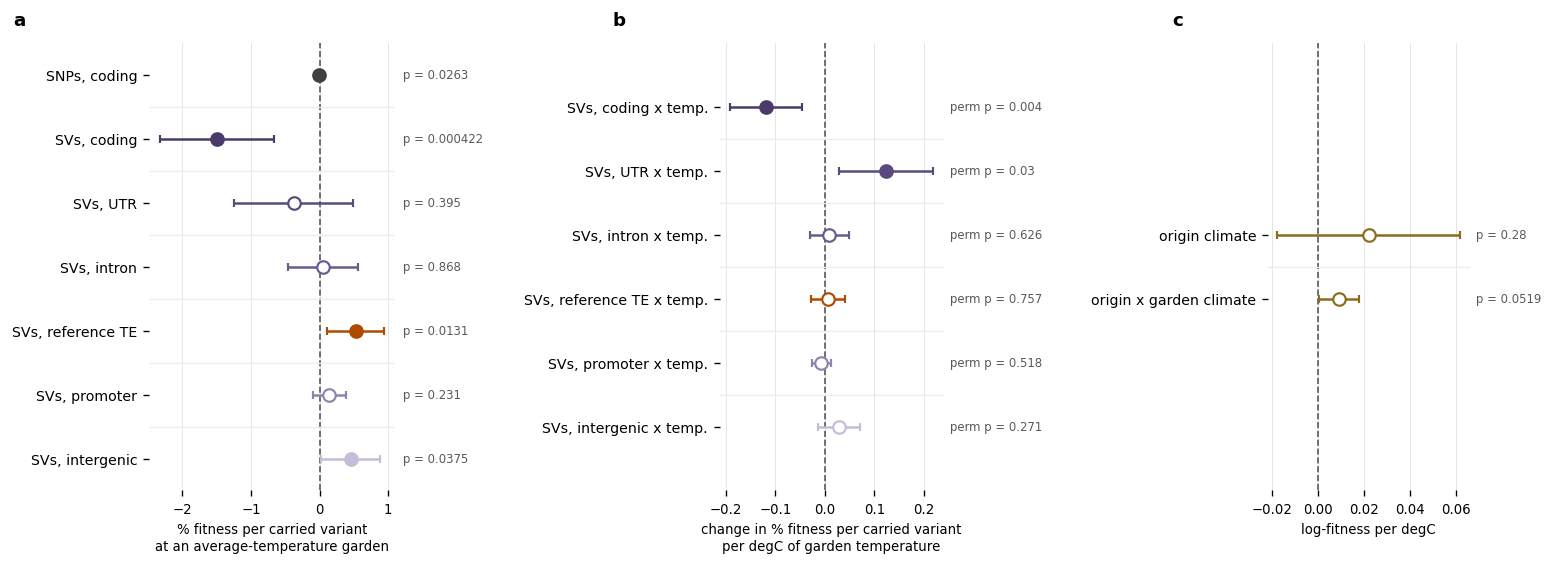

THE FULL MODEL, local adaptation fitted per garden -- all fixed effects

               term  estimate       se             95% CI    Wald p    LRT p   PERM p %/carried variant
        (Intercept) -1.215252 0.101983 [-1.4151, -1.0154] 9.744e-33                                    
            snp_CDS -0.468681 0.210914 [-0.8821, -0.0553]   0.02627                             -0.0047
             sv_CDS -0.286438 0.081238 [-0.4457, -0.1272]  0.000422                             -1.4945
             sv_UTR -0.095295 0.112139 [-0.3151, +0.1245]    0.3954                             -0.3764
          sv_intron +0.022665 0.135965 [-0.2438, +0.2892]    0.8676                             +0.0435
              sv_TE +0.282258 0.113765 [+0.0593, +0.5052]    0.0131                             +0.5241
        sv_promoter +0.206744 0.172456 [-0.1313, +0.5448]    0.2306                             +0.1441
      sv_intergenic +0.287755 0.138298 [+0.0167, +0.5588]   0.03746                            

In [16]:

LRS=SUF
CO2=pd.read_csv(f"{PA}/coef_M2p_reml{LRS}.csv").set_index("term")
VC2=pd.read_csv(f"{PA}/varcomp_M2p_reml{LRS}.csv")
LL2=pd.read_csv(f"{PA}/loglik_M2p_reml{LRS}.csv").iloc[0]
ll2=lambda n: pd.read_csv(f"{PA}/loglik_{n}{LRS}.csv").logLik[0]
LRT2={t: stats.chi2.sf(2*(ll2("M2p_ml")-ll2(f"M2p_ml_drop_{t}")),1) for t in SVT}
OB2=next(t for t in CO2.index if set(t.split(":"))=={"obio1c","bio1c"})
PVX={t:PV(t) for t in VPS}; CLX=PAL2
LBL={**{t:LAB2(t) for t in VPS},"obio1c":"origin climate","bio1c:obio1c":"origin x garden climate"}
BT=BURD; IT=SVT
BLK=[[(t,t,CO2.loc[t,"p"],PVX[t],CLX[t],LBL[t]) for t in BT],
     [(f"{t}:bio1c",t,PP[t],PVX[t],CLX[t],LBL[t]+" x temp.") for t in IT],
     [("obio1c","obio1c",CO2.loc["obio1c","p"],1.0,"#8C6D1F",LBL["obio1c"]),
      (OB2,OB2,PP_LA,1.0,"#8C6D1F",LBL["bio1c:obio1c"])]]
XL=["% fitness per carried variant\nat an average-temperature garden",
    "change in % fitness per carried variant\nper degC of garden temperature",
    "log-fitness per degC"]
NR=max(len(b) for b in BLK)
fig,axs=plt.subplots(1,3,figsize=(14.2,0.42*NR+1.9),
                     gridspec_kw=dict(width_ratios=[1.1,1,0.9],wspace=1.45))
for a,rows,xl,pl in zip(axs,BLK,XL,"abc"):
    style(a); panel(a,pl,x=-0.42 if pl!="a" else -0.50); a.axvline(0,color="0.35",lw=1,ls="--")
    for i,(term,base,pv,k,c,lb) in enumerate(rows):
        e,se=CO2.loc[term,"estimate"]*k,CO2.loc[term,"se"]*k
        a.errorbar(e,i,xerr=1.96*se,fmt="o",color=c,mfc=c if pv<0.05 else "white",
                   mew=1.3,ms=7.5,capsize=2.5,zorder=3)
        if i<len(rows)-1: a.axhline(i+0.5,color="0.93",lw=0.8)
    a.set_yticks(range(len(rows))); a.set_yticklabels([r[5] for r in rows],fontsize=8.5)
    pad=(NR-len(rows))/2.0; a.set_ylim(len(rows)-0.5+pad,-0.5-pad)
    for i,(term,base,pv,k,c,lb) in enumerate(rows):
        tag=("perm p = " if term.endswith(":bio1c") else "p = ")+f"{pv:.3g}"
        a.annotate(tag,xy=(1.03,i),xycoords=("axes fraction","data"),ha="left",va="center",
                   fontsize=7.0,color="0.35",annotation_clip=False)
    a.set_xlabel(xl,fontsize=8)
save(fig,"model_fullmodel_allterms",nb=True); plt.show()
print("THE FULL MODEL, local adaptation fitted per garden -- all fixed effects\n")
out=[]
for t in CO2.index:
    base=t.split(":")[0]; k=PVX.get(base)
    out.append({"term":t,"estimate":f"{CO2.loc[t,'estimate']:+.6f}","se":f"{CO2.loc[t,'se']:.6f}",
                "95% CI":f"[{CO2.loc[t,'estimate']-1.96*CO2.loc[t,'se']:+.4f}, "
                         f"{CO2.loc[t,'estimate']+1.96*CO2.loc[t,'se']:+.4f}]",
                "Wald p":f"{CO2.loc[t,'p']:.4g}",
                "LRT p":(f"{LRT2[base]:.4g}" if t.endswith(":bio1c") and base in LRT2 else ""),
                "PERM p":(f"{PP[base]:.4g}" if t.endswith(":bio1c") and base in PP
                          else (f"{PP_LA:.4g}" if t==OB2 else "")),
                "%/carried variant":(f"{CO2.loc[t,'estimate']*k:+.4f}" if k else "")})
print(pd.DataFrame(out).to_string(index=False))
print("\nINTERACTIONS -- are they significant?")
print(pd.DataFrame([{"interaction":f"{t}:bio1c","%/variant/degC":f"{CO2.loc[t+':bio1c','estimate']*PVX[t]:+.5f}",
                     "LRT p":f"{LRT2[t]:.4g}","PERMUTATION p":f"{PP[t]:.4g}",
                     "p < 0.05":PP[t]<0.05} for t in IT]).to_string(index=False))
print(f"\n  Interactions are judged on the PERMUTATION null ({NPERM} replicates): their Wald/LRT")
print( "  p-values are anti-conservative. Main effects are reported as fitted -- there a Freedman-Lane")
print( "  permutation and a residual bootstrap (20k each) agree with Wald to three decimals.")
print("\nRANDOM EFFECTS"); print(VC2.to_string(index=False))
print(f"\nlogLik {LL2.logLik:.4f}   df {int(LL2.df)}   singular {LL2.singular}")


## 12 · The complete coefficient table

Every fixed effect on the model's own scale — per SD of the standardised rate, which is what R reports —
rather than the per-variant display scale used in the figures. Nothing is omitted.

In [17]:

print("="*84); print("FIXED EFFECTS")
print(pd.DataFrame([{"term":t,"estimate":f"{CO.loc[t,'estimate']:+.5f}","se":f"{CO.loc[t,'se']:.5f}",
                     "z":f"{CO.loc[t,'z']:+.3f}","Wald p":f"{CO.loc[t,'p']:.3g}"} for t in CO.index]
                  ).to_string(index=False))
print(f"\nLIKELIHOOD-RATIO TESTS for the burden x temperature terms (1 df each, {len(SVT)} fitted):")
print(pd.DataFrame([{"term":t,"LRT p":f"{LRT[t]:.5g}","PERMUTATION p":f"{PP[t]:.5g}",
                     "p < 0.05":PP[t]<0.05} for t in SVT]).to_string(index=False))
print("\nRANDOM EFFECTS"); print(VC.to_string(index=False))
print("\nPER-VARIANT SCALING (display only; enters no fit, changes no p-value):")
print(pd.DataFrame([{"context":c,"sd_rate":f"{SCL.loc[c,'sd_rate']:.6f}",
                     "median called":f"{SCL.loc[c,'med_called']:,.0f}",
                     "variants per SD":f"{VPS['sv_'+c]:.1f}"} for c in SCL.index]).to_string(index=False))


FIXED EFFECTS
               term estimate      se       z   Wald p
        (Intercept) -1.21525 0.10198 -11.916 9.74e-33
            snp_CDS -0.46868 0.21091  -2.222   0.0263
             sv_CDS -0.28644 0.08124  -3.526 0.000422
             sv_UTR -0.09530 0.11214  -0.850    0.395
          sv_intron +0.02267 0.13597  +0.167    0.868
              sv_TE +0.28226 0.11377  +2.481   0.0131
        sv_promoter +0.20674 0.17246  +1.199    0.231
      sv_intergenic +0.28776 0.13830  +2.081   0.0375
             cactus -0.00900 0.13078  -0.069    0.945
             obio1c +0.02193 0.02031  +1.080     0.28
       sv_CDS:bio1c -0.02280 0.00713  -3.198  0.00139
       sv_UTR:bio1c +0.03130 0.01235  +2.534   0.0113
    sv_intron:bio1c +0.00481 0.01042  +0.461    0.645
        sv_TE:bio1c +0.00372 0.00939  +0.396    0.692
  sv_promoter:bio1c -0.01071 0.01404  -0.763    0.446
sv_intergenic:bio1c +0.01848 0.01377  +1.343    0.179
       bio1c:obio1c +0.00888 0.00438  +2.028   0.0426

LIKELIHOOD-RA

## 13 · Reading it

### The result

**Carrying a structural variant in coding sequence costs about 1.5 % of founder fitness per variant** —
−1.49 % at a garden of average temperature, 95 % CI [−2.34, −0.65], p = 5.6 × 10⁻⁴, with founder origin
climate and its garden-climate interaction in the model.

It is **broad, not concentrated**:

| | |
|---|---|
| frequency (§6) | rare −2.49 %, common −0.97 % per variant; contrast p = 0.08 |
| size (§7) | −1.02 → −1.25 → −2.24 per variant; omnibus across bins p = 0.56 |
| ecotypes (§9) | 231 leave-one-out refits, all negative, never within 2.9 SE of zero |
| dropping 20 % at random (§10) | 600 refits, 100 % negative, 99 % still p < 0.05 |
| gardens (§5) | negative in 27 of 31 gardens |

Neither stratification isolates a driver. Estimates order as purifying selection predicts — rarer and
larger variants worse per variant — but in neither case can the strata be told apart, and the effect
survives every partition precisely because it does not rest on a narrow subset.

### What does not hold

**The temperature interactions are weak** (§3). Coding SVs give the only one near significance,
LRT p = 0.043; reference TE and promoter are at 0.093 and 0.095. Fitted *without* the local-adaptation
terms all three are clearly significant; adding origin climate × garden climate attenuates the estimates by
29–50 % while leaving the standard errors essentially unchanged — the signature of confounding rather than
of lost precision. A ~100× shift in the coding interaction (0.0004 → 0.043) is the finding here, wherever
one puts a threshold. Those uncontrolled fits are in the registry.

### What this does not establish

⚠ **Robustness is not identification.** §§9–10 show the estimate does not depend on particular ecotypes.
Whether something *correlated with* SV burden — rather than the SVs — causes the fitness difference is a
separate question. The local-adaptation control is the relevant test and leaves `sv_CDS` almost untouched
(0.22 SE), but `obio1c` is a single summary of provenance, so the control is incomplete.

⚠ **The control tests the interactions much harder than the main effects.** `obio1c:bio1c` is an
interaction and therefore near-orthogonal to the burden main effects; the main-effect counterpart is
`obio1c` itself (p ≈ 0.04). The coding-SV effect is robust to provenance *as far as this design can tell*,
not established to the standard by which the interactions are refuted.

⚠ **Private variants are an assembly artifact** (§6). They are reported only within the cactus panel, and
even there the non-monotone result is a caution about the bin rather than a finding.

⚠ The per-garden panels (§5, §12) come from the fitted model, so they carry every covariate. A temperature
trend in them is the §3 interaction, which is marginal at best.

### Suggested reporting

> Carrying a structural variant in coding sequence costs about 1.5 % of founder fitness per variant. The
> effect holds with founder origin climate and its garden-climate interaction in the model, appears in both
> sequencing panels independently, is not concentrated in rare or in large variants, and is not driven by
> any subset of ecotypes. No climate-dependent SV burden effect survives the local-adaptation control.

## As run

**The fit.** `_sv_burden_pooled_models.R` with
`POOL_SET=sv6 BURDEN_ORIGIN=all ONESTAGE_DIR=onestage_all FINAL_OUT=final_models_pooled_all`,
`EXTRA_FIXED="obio1c + obio1c:bio1c"`, `RE_DROP=fid`, tasks 0–5 (`_submit_main_refid.sh`). Outputs carry
the suffix `_x_obio1cobio1cbio1c_refid`. Nothing is refitted in this notebook; every number is read from
the R output.

- **Burdens.** `founder_burden_event.csv` — truvari-collapsed SV **events**, insertions and deletions summed
  within a context, origin class `all`, z-scored across the 231 founders. The stratified sections read
  `founder_burden_event_{freq,size}.csv` from `_sv_burden_strata.py`, which lowers the carrier floor to 1
  for the frequency bins and holds it at 2 for the size bins so the singleton class cannot leak in.
- **`RE_DROP=fid`.** The independent founder intercept estimated 4.9 × 10⁻⁷ in the unpruned fit. Removing
  it leaves the log-likelihood and every coefficient and standard error unchanged to five decimals, costs
  one parameter, and leaves no variance component at the boundary.
- **`obio1c` vs `bio1c`.** `obio1c` is the **founder's origin** bio1, centred over the founders and *not*
  standardised (hence the rescaling in §3); `bio1c` is the **garden's** bio1, centred over the 31 gardens.
  lme4 names the interaction `bio1c:obio1c` by model-frame order; the load cell resolves the spelling.
- **Per-variant scaling.** `sd_rate × med_called` from the arm's `pooled_rate_scale*.csv`. A display scaling
  only. `RE_DROP` does not change the burdens, so the reported fit shares the scale file of its unpruned
  twin. Each *stratified* arm has its own file: before 2026-09-29 the name was tagged only with `SUBSET`
  and stratified arms overwrote one another; `_regen_rate_scales.py` rebuilt the lost ones, validated by
  reproducing the survivors to machine precision.
- **LRTs.** Read from the named `loglik_*.csv` files, never by globbing: this directory also holds
  `SUBSET=`, `RE_DROP=` and other `EXTRA_FIXED` runs.
- **Diagnostics (§§7–10).** Computed here, not in R. The response is averaged over the 31 gardens, reducing
  the mixed model to a 231-observation GLS whose main effects reproduce the LMM's to machine precision (§7
  verifies it) because `bio1c` is centred and the design is balanced. Leave-one-out and delete-d refits
  *condition* on the retained founders — the covariance is re-inverted on the retained submatrix of `V`,
  not row-deleted from `V⁻¹`, which would be a different model.
- **Every other specification** ever fitted — `shared` origin filter, TE dropped, no local-adaptation
  control, split insertions/deletions, single-technology panels — is indexed in
  `results/sv_adaptive/model_specs.csv` and `model_registry.csv`, each fit carrying a `spec_*.csv` with its
  literal formula, founder counts, singularity flag and git commit.